# Clasificación desbalanceada con XGBoost
**Alondra E. Matos Mendoza**

## 1. Introducción y descripción del problema

Predecir fallas industriales en las próximas 24 horas con un escenario sintético de sensores. Se comparan cinco configuraciones de XGBoost: sin balanceo, ROS, RUS, SMOTE y ponderación. MCC en CV externa es el criterio principal; kappa de Cohen complementa la evaluación.

Este notebook es autónomo. Genera sus datos, define sus funciones y ejecuta el estudio completo sin cargar modelos, variables ni resultados de otros notebooks. La generación, la partición y los folds se conservan para permitir comparaciones posteriores. La selección probabilística utiliza **Log Loss**, con desempate por Brier y simplicidad.


### Entorno


In [1]:
# Librerías
import importlib.metadata as metadata
import inspect
import hashlib
import json
import platform
from copy import deepcopy
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy.stats import norm
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, log_loss, matthews_corrcoef, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from imblearn.utils import check_sampling_strategy
from xgboost import XGBClassifier

SEED = 42
paquetes = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'imbalanced-learn',
            'xgboost', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']
versiones = {p: metadata.version(p) for p in paquetes}
print('Python:', platform.python_version())
display(pd.Series(versiones, name='Versión').to_frame())
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 115, 'savefig.dpi': 180, 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
COLORES = {'XGB': '#c57237', 'NONE': '#52697a',
           'SIGMOID': '#087f8c', 'ISOTONIC': '#b45b78'}
pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 160)

def tabla(datos, decimales=4):
    """Formato HTML sin modificar los valores usados en los cálculos."""
    formatos = {c: lambda v: str(int(v)) for c in datos.columns if c == 'k_neighbors'}
    html = datos.to_html(float_format=lambda v: f'{v:.{decimales}f}', formatters=formatos, na_rep='N/A', border=0)
    display(HTML('<div style="overflow-x:auto;max-width:100%">' + html + '</div>'))

inicio = perf_counter()
FAMILIA = 'XGB'
NOMBRE_MODELO = 'XGBoost'


Python: 3.12.4


,Versión
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
imbalanced-learn,0.14.2
xgboost,3.4.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


## 2. Generación y análisis del dataset

El dataset es sintético y simula lecturas de sensores de componentes industriales, con el objetivo de predecir si
un componente fallará en las próximas 24 horas. La clase positiva (falla) es poco frecuente.


| Columna                  | Descripción                                                                                                                                                                                                                                                       |
| ------------------------ | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `sensor_1` – `sensor_12` | Doce lecturas numéricas de sensores de un componente industrial (vibración, temperatura, presión, corriente, etc.), ya normalizadas por el simulador. No todas son igual de informativas: algunas están correlacionadas entre sí y otras son prácticamente ruido. |
| `falla`                  | Variable objetivo binaria: `1` si el componente falló en las siguientes 24 horas y `0` si no. Es la clase minoritaria (\~3% de las filas).                                                                                                                        |

Dimensiones: 6,000 filas × 13 columnas (12 sensores + objetivo)


,Tipo,Faltantes
sensor_1,float64,0
sensor_2,float64,0
sensor_3,float64,0
sensor_4,float64,0
sensor_5,float64,0
sensor_6,float64,0
sensor_7,float64,0
sensor_8,float64,0
sensor_9,float64,0
sensor_10,float64,0


,Clase,Observaciones,Proporción
0,Sin falla (0),5799,0.9665
1,Falla (1),201,0.0335


Prevalencia observada: 3.35%; razón negativos/positivos: 28.85:1


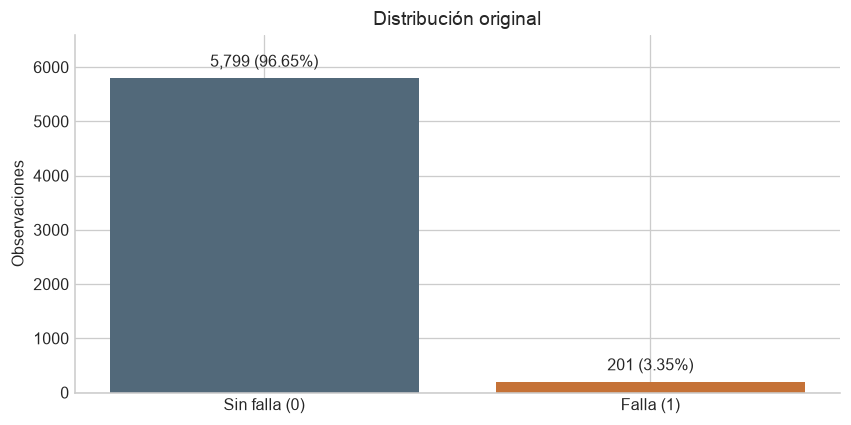

In [2]:
# Creación del dataset 
X, y = make_classification(
    n_samples=6000,
    n_features=12,
    n_informative=6,
    n_redundant=2,
    n_repeated=0,
    n_clusters_per_class=2,
    weights=[0.97, 0.03],
    flip_y=0.01,
    class_sep=0.9,
    random_state=42
)
columnas = [f"sensor_{i}" for i in range(1, 13)]
df = pd.DataFrame(X, columns=columnas)
df['falla'] = y

# Características
X = df[columnas].copy()
y = df['falla'].copy()
conteos = y.value_counts().sort_index()
prevalencia = y.mean()
razon = conteos.loc[0] / conteos.loc[1]
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas (12 sensores + objetivo)')
display(pd.DataFrame({'Tipo': df.dtypes.astype(str), 'Faltantes': df.isna().sum()}))
distribucion = pd.DataFrame({'Clase': ['Sin falla (0)', 'Falla (1)'],
                             'Observaciones': conteos.to_numpy(),
                             'Proporción': (conteos / len(y)).to_numpy()})
tabla(distribucion)
print(f'Prevalencia observada: {prevalencia:.2%}; razón negativos/positivos: {razon:.2f}:1')
fig, ax = plt.subplots(figsize=(7.5, 3.8))
barras = ax.bar(distribucion['Clase'], conteos.to_numpy(), color=['#52697a', '#c57237'])
ax.bar_label(barras, labels=[f'{n:,} ({n/len(y):.2%})' for n in conteos], padding=5)
ax.set(title='Distribución original', ylabel='Observaciones', ylim=(0, 6600))
plt.tight_layout()
plt.show()


El dataset contiene 201 fallas entre 6,000 observaciones (3.35%), mientras que los casos restantes corresponden a componentes sin falla. Esto significa que, por cada componente que falla, hay aproximadamente 29 que no presentan fallas. Los 12 sensores son variables numéricas y no presentan valores faltantes, por lo que el principal desafío es identificar un evento poco frecuente en un escenario donde las clases no están perfectamente separadas.

Este desbalance hace que la exactitud pueda resultar engañosa: un modelo que siempre prediga que no habrá fallas alcanzaría cerca del 97% de exactitud, pero sería incapaz de detectar una sola falla. Por esta razón, utilizaremos MCC como métrica principal y kappa de Cohen como complementaria, complementadas con precision y recall para entender cuántas fallas logramos identificar y cuántas falsas alarmas generamos. 

En particular, se prioriza MCC porque mide qué tan bien el modelo distingue entre componentes que fallan y los que no, considerando los aciertos y errores de ambas clases, incluso cuando están desbalanceadas. En cambio, kappa de Cohen evalúa qué tanto coinciden las predicciones con los resultados reales, descontando la coincidencia que se esperaría por azar según las proporciones de cada clase. Así, mientras MCC se enfoca en la capacidad de clasificación del modelo, kappa aporta una medida complementaria del acuerdo alcanzado.

## 3. Partición estratificada

Se reserva 20% como test. La estratificación conserva aproximadamente la prevalencia. Train (4,800) se usa para todos los ajustes y elecciones. Test (1,200) se utiliza después de fijar modelo, umbrales y calibrador.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
particion = pd.DataFrame([
    {'Conjunto': nombre, 'Filas': len(yy), 'Negativos': int((yy == 0).sum()),
     'Positivos': int((yy == 1).sum()), 'Prevalencia': yy.mean()}
    for nombre, yy in [('Train', y_train), ('Test', y_test)]
])
tabla(particion)
assert set(X_train.index).isdisjoint(X_test.index)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X_train, y_train))


,Conjunto,Filas,Negativos,Positivos,Prevalencia
0,Train,4800,4639,161,0.0335
1,Test,1200,1160,40,0.0333


La partición estratificada permitió mantener prácticamente la misma proporción de fallas en ambos conjuntos: 161 casos positivos en entrenamiento (3.35%) y 40 en prueba (3.33%). Esto asegura que ambos conjuntos tengan una distribución similar a la original, sin compartir observaciones.

El conjunto de entrenamiento se utilizará para ajustar y seleccionar los modelos, mientras que el de prueba se reservará para evaluar su desempeño final. Es importante considerar que solo contamos con 40 fallas en test, por lo que cada falla detectada o no detectada representa un cambio de 2.5 puntos porcentuales en el recall. Esto significa que pequeñas diferencias entre modelos deben interpretarse con cautela, especialmente al evaluar la detección de fallas y la calibración de probabilidades.


## 4. Modelos y estrategias de balanceo

Se compara un modelo base sin balanceo con cuatro tratamientos del desbalance, manteniendo los hiperparámetros del clasificador.

### Modelo base

- **XGBoost:** se incluye por ser uno de los algoritmos de *boosting* más utilizados en aplicaciones prácticas de aprendizaje automático, particularmente en problemas de clasificación con datos tabulares. Su capacidad para capturar relaciones no lineales e interacciones entre variables lo convierte en una alternativa flexible para este problema tabular. Utiliza árboles de profundidad 3, 200 iteraciones, tasa de aprendizaje de 0.05, método de histogramas (`tree_method="hist"`) y un solo hilo de ejecución (`n_jobs=1`). Los árboles no requieren estandarización; únicamente `XGB_3` incorpora escalado antes de SMOTE. No se aplica búsqueda de hiperparámetros del clasificador ni *early stopping*. Estos parámetros se mantienen constantes en todas las variantes.

### Estrategias de balanceo

Se evalúan cuatro estrategias para tratar el desbalance de clases:

- **Random Oversampling:** incrementa la representación de la clase minoritaria mediante la duplicación aleatoria de observaciones existentes.
- **Random Undersampling:** reduce la representación de la clase mayoritaria mediante la eliminación aleatoria de observaciones.
- **SMOTE:** genera observaciones sintéticas de la clase minoritaria a partir de la interpolación entre observaciones vecinas.
- **Ponderación de clases:** asigna pesos diferenciados a las clases durante el entrenamiento, sin modificar la cantidad de observaciones.
  - **XGBoost:** utiliza `scale_pos_weight`, calculado como la razón entre el número de observaciones negativas y positivas.

### Configuración del remuestreo

ROS, RUS y SMOTE conservan semilla 42 y SMOTE optimiza `k_neighbors` entre 1, 3, 5, 7, 9, 11, 15 y 21. La razón positivos/negativos se selecciona entre 29 valores; SMOTE busca conjuntamente los ocho valores de vecinos mediante CV interna; el balanceo completo es un candidato de referencia.

### Estandarización antes de SMOTE

SMOTE utiliza distancias para identificar vecinos y generar ejemplos sintéticos. Estandarizar evita que diferencias de escala dominen esas distancias. XGB_3 utiliza el orden StandardScaler → SMOTEAuditado → XGBoost. Los árboles no requieren escalado por sí mismos; las otras cuatro configuraciones permanecen sin escalador.

El escalador aprende exclusivamente con el subentrenamiento de cada fold, antes del remuestreo. Las observaciones reservadas para validación o calibración y las de test solo se transforman con el escalador ajustado. SMOTE se aplica únicamente durante fit, dentro de imblearn.pipeline.Pipeline. Las estadísticas y tamaños del escalado se contrastan con sus datos locales de ajuste.


In [4]:
XGB_PARAMS = dict(
    objective='binary:logistic', eval_metric='logloss', random_state=42,
    tree_method='hist', n_estimators=200, max_depth=3, learning_rate=0.05,
    min_child_weight=1, subsample=1.0, colsample_bytree=1.0,
    reg_lambda=1.0, reg_alpha=0.0, n_jobs=1,
)

class FoldWeightedXGBClassifier(ClassifierMixin, BaseEstimator):
    """Calcula scale_pos_weight exclusivamente con y recibido por fit."""
    def __init__(self, xgb_params=None):
        self.xgb_params = xgb_params

    def fit(self, X, y):
        y_array = np.asarray(y)
        n_pos = int(np.sum(y_array == 1))
        n_neg = int(np.sum(y_array == 0))
        if n_pos == 0 or n_neg == 0:
            raise ValueError('El subentrenamiento necesita ambas clases.')
        self.scale_pos_weight_ = n_neg / n_pos
        self.n_fit_ = len(y_array)
        params = dict(self.xgb_params or {})
        self.estimator_ = XGBClassifier(**params, scale_pos_weight=self.scale_pos_weight_)
        self.estimator_.fit(X, y)
        self.classes_ = self.estimator_.classes_
        self.n_features_in_ = self.estimator_.n_features_in_
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def predict(self, X):
        return self.estimator_.predict(X)

ESTRATEGIAS = {0: 'Sin balanceo', 1: 'Random Oversampling',
               2: 'Random Undersampling', 3: 'SMOTE', 4: 'Ponderación'}


class ConteosRemuestreoMixin:
    """Instrumenta el resultado real de fit_resample sin cambiar el algoritmo."""
    def fit_resample(self, X, y, **params):
        self.conteos_antes_ = {c: int(np.sum(np.asarray(y) == c)) for c in [0, 1]}
        X_res, y_res = super().fit_resample(X, y, **params)
        self.conteos_despues_ = {c: int(np.sum(np.asarray(y_res) == c)) for c in [0, 1]}
        self.n_entrada_ = len(y)
        self.n_salida_ = len(y_res)
        # La comprobación usa el plan de imbalanced-learn, que incorpora sus redondeos.
        for clase in [0, 1]:
            esperado = (self.conteos_antes_[clase] + self.sampling_strategy_.get(clase, 0)
                        if self._sampling_type == 'over-sampling'
                        else self.sampling_strategy_.get(clase, self.conteos_antes_[clase]))
            assert self.conteos_despues_[clase] == esperado
        assert self.n_salida_ == sum(self.conteos_despues_.values())
        return X_res, y_res

class RandomOverSamplerAuditado(ConteosRemuestreoMixin, RandomOverSampler):
    pass

class RandomUnderSamplerAuditado(ConteosRemuestreoMixin, RandomUnderSampler):
    pass

class SMOTEAuditado(ConteosRemuestreoMixin, SMOTE):
    pass

def construir_modelo(estrategia, sampling_strategy=1.0, k_neighbors=5):
    pasos = []
    if estrategia == 3:
        pasos.append(('scaler', StandardScaler()))
    muestreadores = {
        1: RandomOverSamplerAuditado(sampling_strategy=sampling_strategy, random_state=42),
        2: RandomUnderSamplerAuditado(sampling_strategy=sampling_strategy, random_state=42),
        3: SMOTEAuditado(sampling_strategy=sampling_strategy, random_state=42, k_neighbors=k_neighbors),
    }
    if estrategia in muestreadores:
        pasos.append(('sampler', muestreadores[estrategia]))
    if estrategia == 4:
        modelo = FoldWeightedXGBClassifier(xgb_params=deepcopy(XGB_PARAMS))
    else:
        modelo = XGBClassifier(**XGB_PARAMS)
    return Pipeline(pasos + [('modelo', modelo)])

AUDITORIA_ESCALADO = []

def verificar_escalado_fit(estimador, datos_fit, datos_reservados=None):
    """Contrasta las estadísticas del scaler con su subentrenamiento real."""
    if 'scaler' not in estimador.named_steps:
        return
    scaler = estimador.named_steps['scaler']
    assert isinstance(scaler, StandardScaler)
    assert list(estimador.named_steps)[0] == 'scaler'
    assert int(scaler.n_samples_seen_) == len(datos_fit)
    valores = np.asarray(datos_fit, dtype=float)
    np.testing.assert_allclose(scaler.mean_, valores.mean(axis=0), rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(scaler.var_, valores.var(axis=0), rtol=1e-10, atol=1e-12)
    if datos_reservados is not None:
        assert set(datos_fit.index).isdisjoint(datos_reservados.index)
    if 'sampler' in estimador.named_steps:
        assert estimador.named_steps['sampler'].n_entrada_ == len(datos_fit)
    AUDITORIA_ESCALADO.append({
        'N_fit':len(datos_fit),
        'N_reservados':0 if datos_reservados is None else len(datos_reservados),
        'SMOTE':isinstance(estimador.named_steps.get('sampler'), SMOTEAuditado),
    })

def probabilidad_positiva(modelo, datos):
    """Localiza la columna de la clase 1; no presupone su posición."""
    idx = np.flatnonzero(np.asarray(modelo.classes_) == 1)
    assert len(idx) == 1
    p = np.asarray(modelo.predict_proba(datos))[:, idx[0]]
    assert p.shape == (len(datos),)
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p


# La malla es predefinida; el óptimo se refiere únicamente a sus candidatos.
MALLA_UMBRALES = np.linspace(0.005, 0.995, 199)

def metricas_decision(verdad, pred):
    return {
        'Accuracy': accuracy_score(verdad, pred),
        'MCC': matthews_corrcoef(verdad, pred),
        'Kappa': cohen_kappa_score(verdad, pred),
        'Precision': precision_score(verdad, pred, zero_division=0),
        'Recall': recall_score(verdad, pred, zero_division=0),
        'F1': f1_score(verdad, pred, zero_division=0),
        'Pred_positivas': int(np.sum(pred)),
    }

def evaluar_probabilidades(verdad, p):
    p = np.asarray(p, dtype=float)
    return {
        'ROC_AUC': roc_auc_score(verdad, p),
        'AP': average_precision_score(verdad, p),
        'Brier': brier_score_loss(verdad, p),
        'LogLoss': log_loss(verdad, np.column_stack([1-p, p]), labels=[0, 1]),
        'Prob_media': np.mean(p), 'Prevalencia': np.mean(verdad),
    }

def evaluar(verdad, p, umbral):
    """Exige un umbral explícito seleccionado exclusivamente con train."""
    assert np.isfinite(umbral) and 0 <= umbral <= 1
    pred = (np.asarray(p) >= umbral).astype(int)
    return {'Umbral': float(umbral), **metricas_decision(verdad, pred),
            **evaluar_probabilidades(verdad, p)}

def curva_mcc(verdad, p):
    return np.array([matthews_corrcoef(verdad, np.asarray(p) >= t)
                     for t in MALLA_UMBRALES])

def seleccionar_umbral(verdad, p):
    puntuaciones = curva_mcc(verdad, p)
    # Ante empate numérico de MCC, el mayor umbral evita alarmas adicionales.
    candidatos = np.flatnonzero(np.isclose(puntuaciones, puntuaciones.max(), rtol=0, atol=1e-12))
    return float(MALLA_UMBRALES[candidatos[-1]])


def generar_oof(plantilla, datos, etiquetas, n_splits=5, devolver_folds=False):
    """Predicciones OOF locales; devuelve los folds para reutilizar la evaluación."""
    interna = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    p = np.full(len(etiquetas), np.nan)
    asignacion = np.full(len(etiquetas), -1, dtype=int)
    for fold, (it, iv) in enumerate(interna.split(datos, etiquetas), start=1):
        assert set(it).isdisjoint(iv)
        estimador = clone(plantilla)
        if 'scaler' in estimador.named_steps:
            assert not hasattr(estimador.named_steps['scaler'], 'mean_')
        estimador.fit(datos.iloc[it], etiquetas.iloc[it])
        p[iv] = probabilidad_positiva(estimador, datos.iloc[iv])
        verificar_escalado_fit(estimador, datos.iloc[it], datos.iloc[iv])
        assert np.all(asignacion[iv] == -1)
        asignacion[iv] = fold
    assert np.all(asignacion > 0) and np.isfinite(p).all()
    return (p, asignacion) if devolver_folds else p


### Refinamiento de intensidad entre 0.05 y 0.25

Se añaden intensidades cada 0.01 en el intervalo [0.05, 0.25], conservando todos los puntos anteriores: **29 razones de muestreo**. Se mantienen k_neighbors=[1, 3, 5, 7, 9, 11, 15, 21]. ROS y RUS evalúan 29 razones cada uno; SMOTE evalúa **232 parejas**, para un total de **290 candidatos por búsqueda local**. La razón representa positivos/negativos después de remuestrear, no la prevalencia positiva.

Cada candidato genera OOF con tres folds internos, ajusta su umbral por MCC OOF agrupado y obtiene MCC medio y SD entre folds. Se conserva el orden: mayor MCC, menor SD, menor sampling_strategy y, solo para SMOTE, menor k_neighbors. Los cinco folds externos reservados evalúan la búsqueda completa. Escalado y remuestreo permanecen dentro del pipeline, con factibilidad y caché identificadas por datos locales y ambas mallas.

Este refinamiento se decide después de observar CV previa. Repetir la comparación de mallas sobre los mismos folds puede adaptar el espacio de búsqueda a esos resultados; cualquier ventaja necesita confirmación con datos nuevos. Test no participa en ninguna selección.


In [5]:
# Refinamiento de 0.05 a 0.25 cada 0.01, conservando todos los puntos anteriores.
SAMPLING_STRATEGIES = sorted(set(
    [i / 100 for i in range(5, 26)]
    + [0.04, 0.045, 0.075, 0.125, 0.35, 0.50, 0.75, 1.00]
))
K_NEIGHBORS = [1, 3, 5, 7, 9, 11, 15, 21]
N_CANDIDATOS_SMOTE = len(SAMPLING_STRATEGIES) * len(K_NEIGHBORS)
N_CANDIDATOS_TOTALES = 2*len(SAMPLING_STRATEGIES) + N_CANDIDATOS_SMOTE
FOLDS_BUSQUEDA = 3
BUSQUEDAS_CACHE = {}
CACHE_HITS = 0
AUDITORIA_CALIBRACION = []

def huella_datos(datos, etiquetas):
    h = hashlib.sha256(pd.util.hash_pandas_object(datos, index=True).to_numpy().tobytes())
    h.update(np.asarray(etiquetas, dtype=np.int64).tobytes())
    return h.hexdigest()

def parametros_remuestreo(resultado):
    parametros = {'sampler__sampling_strategy': resultado['sampling_strategy']}
    if resultado['k_neighbors'] is not None:
        parametros['sampler__k_neighbors'] = int(resultado['k_neighbors'])
    return parametros

def factibilidad_sampling(plantilla, etiquetas, valor, k_neighbors=None):
    sampler = plantilla.named_steps['sampler']
    y_local = np.asarray(etiquetas)
    negativos = int(np.sum(y_local == 0)); positivos = int(np.sum(y_local == 1))
    if not (0 < positivos < negativos):
        return False, 'Se requieren ambas clases y falla=1 como minoritaria.'
    if not (positivos/negativos < valor <= 1):
        return False, 'La razón debe superar positivos/negativos original y no exceder 1.'
    try:
        plan = check_sampling_strategy(float(valor), y_local, sampler._sampling_type)
        if sampler._sampling_type == 'under-sampling' and plan.get(0, negativos) >= negativos:
            return False, 'El redondeo no permite eliminar ninguna observación mayoritaria.'
        if isinstance(sampler, SMOTE):
            k = sampler.k_neighbors if k_neighbors is None else k_neighbors
            if not isinstance(k, (int, np.integer)) or k < 1:
                return False, f'k_neighbors={k} debe ser un entero positivo.'
            if positivos <= k:
                return False, f'SMOTE: {positivos} positivos no bastan para k_neighbors={k}.'
    except ValueError as exc:
        return False, str(exc)
    return True, ''

def buscar_sampling(mid, plantilla, datos, etiquetas, n_splits=3):
    """Selecciona la pareja de SMOTE solo con los datos locales recibidos."""
    global CACHE_HITS
    es_smote = isinstance(plantilla.named_steps['sampler'], SMOTE)
    firma = repr(sorted((k, repr(v)) for k, v in plantilla.get_params(deep=True).items()
                        if '__' in k and k not in
                        {'sampler__sampling_strategy', 'sampler__k_neighbors'}))
    huella = huella_datos(datos, etiquetas)
    clave = ('smote-conjunto-v1', mid, huella, n_splits,
             tuple(SAMPLING_STRATEGIES), tuple(K_NEIGHBORS), firma)
    if clave in BUSQUEDAS_CACHE:
        CACHE_HITS += 1
        return BUSQUEDAS_CACHE[clave]
    interna = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    particiones = list(interna.split(datos, etiquetas))
    candidatos = [(float(a), k) for a in SAMPLING_STRATEGIES
                  for k in (K_NEIGHBORS if es_smote else [None])]
    filas, predicciones = [], {}
    for valor, k in candidatos:
        motivos = []
        for fold, (it, iv) in enumerate(particiones, start=1):
            assert set(it).isdisjoint(iv)
            ok, motivo = factibilidad_sampling(plantilla, etiquetas.iloc[it], valor, k)
            if not ok: motivos.append(f'Fold interno {fold}: {motivo}')
        ok, motivo = factibilidad_sampling(plantilla, etiquetas, valor, k)
        if not ok: motivos.append(f'Reentrenamiento local: {motivo}')
        fila = {'ID': mid, 'sampling_strategy': valor,
                'k_neighbors': np.nan if k is None else int(k),
                'Factible': not motivos, 'Motivo': ' | '.join(motivos),
                'N_ajuste': len(etiquetas), 'Huella_ajuste': huella}
        if motivos:
            filas.append(fila)
            continue
        candidato = clone(plantilla).set_params(**parametros_remuestreo(
            {'sampling_strategy':valor, 'k_neighbors':k}))
        try:
            p, asignacion = generar_oof(candidato, datos, etiquetas,
                                        n_splits=n_splits, devolver_folds=True)
        except ValueError as exc:
            fila.update(Factible=False, Motivo='Error de remuestreo/ajuste: '+str(exc))
            filas.append(fila)
            continue
        t = seleccionar_umbral(etiquetas, p)
        mccs = [matthews_corrcoef(np.asarray(etiquetas)[asignacion == f], p[asignacion == f] >= t)
                for f in range(1, n_splits+1)]
        fila.update(Umbral_OOF=t, MCC_interno_media=float(np.mean(mccs)),
                    MCC_interno_sd=float(np.std(mccs, ddof=1)),
                    MCC_OOF=matthews_corrcoef(etiquetas, p >= t),
                    **{f'MCC_interno_{j}':m for j,m in enumerate(mccs, start=1)})
        filas.append(fila)
        predicciones[(valor, k)] = p
    tabla_busqueda = pd.DataFrame(filas)
    factibles = tabla_busqueda.loc[tabla_busqueda['Factible']]
    if factibles.empty:
        raise ValueError(f'{mid}: ningún candidato factible. '+tabla_busqueda['Motivo'].str.cat(sep=' | '))
    criterios = ['MCC_interno_media', 'MCC_interno_sd', 'sampling_strategy']
    if es_smote: criterios.append('k_neighbors')
    mejor = factibles.sort_values(criterios, ascending=[False]+[True]*(len(criterios)-1),
                                 kind='stable').iloc[0]
    valor = float(mejor['sampling_strategy'])
    k = int(mejor['k_neighbors']) if es_smote else None
    mascara_k = (tabla_busqueda['k_neighbors'].eq(k) if es_smote
                 else tabla_busqueda['k_neighbors'].isna())
    tabla_busqueda['Seleccionado'] = tabla_busqueda['sampling_strategy'].eq(valor) & mascara_k
    assert tabla_busqueda['Seleccionado'].sum() == 1
    resultado = {'sampling_strategy':valor, 'k_neighbors':k,
                 'umbral':float(mejor['Umbral_OOF']), 'oof':predicciones[(valor, k)],
                 'tabla':tabla_busqueda, 'huella':huella, 'n_ajuste':len(etiquetas)}
    BUSQUEDAS_CACHE[clave] = resultado
    return resultado

class SeleccionSamplingCV(ClassifierMixin, BaseEstimator):
    """Busca ambos parámetros de SMOTE solo con las filas recibidas por fit."""
    def __init__(self, plantilla=None, mid=None, n_splits=3):
        self.plantilla = plantilla
        self.mid = mid
        self.n_splits = n_splits

    def fit(self, X, y):
        datos = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        etiquetas = pd.Series(np.asarray(y), index=datos.index)
        resultado = buscar_sampling(self.mid, self.plantilla, datos, etiquetas, self.n_splits)
        self.sampling_strategy_ = resultado['sampling_strategy']
        self.k_neighbors_ = resultado['k_neighbors']
        self.umbral_ = resultado['umbral']
        self.estimador_ = clone(self.plantilla).set_params(
            **parametros_remuestreo(resultado)).fit(datos, etiquetas)
        verificar_escalado_fit(self.estimador_, datos)
        self.classes_ = self.estimador_.classes_
        self.n_features_in_ = self.estimador_.n_features_in_
        self.huella_ajuste_ = resultado['huella']
        AUDITORIA_CALIBRACION.append({'ID':self.mid, 'N_ajuste':len(y),
            'Huella_ajuste':self.huella_ajuste_, 'sampling_strategy':self.sampling_strategy_,
            'k_neighbors':self.k_neighbors_})
        return self

    def predict_proba(self, X):
        return self.estimador_.predict_proba(X)

    def predict(self, X):
        return (probabilidad_positiva(self, X) >= self.umbral_).astype(int)


### Configuraciones experimentales

In [6]:
# Cada ID apunta a un pipeline sin entrenar; CV lo clona en cada fold.
modelos = {f'{FAMILIA}_{j}': construir_modelo(j) for j in range(5)}
catalogo = pd.DataFrame([
    {'ID':mid, 'Familia':FAMILIA, 'Modelo':NOMBRE_MODELO,
     'Estrategia':ESTRATEGIAS[int(mid[-1])],
     'Tratamiento':'scale_pos_weight por fold' if mid.endswith('_4') else ESTRATEGIAS[int(mid[-1])]}
    for mid in modelos
]).set_index('ID')
display(catalogo)


,Familia,Modelo,Estrategia,Tratamiento
ID,,,,
XGB_0,XGB,XGBoost,Sin balanceo,Sin balanceo
XGB_1,XGB,XGBoost,Random Oversampling,Random Oversampling
XGB_2,XGB,XGBoost,Random Undersampling,Random Undersampling
XGB_3,XGB,XGBoost,SMOTE,SMOTE
XGB_4,XGB,XGBoost,Ponderación,scale_pos_weight por fold


El catálogo distingue cinco procedimientos de XGBoost: un baseline y cuatro tratamientos del desbalance. **XGB_0** permite evaluar cuánto aporta balancear frente al mismo algoritmo sin ese tratamiento. Los IDs 1 a 3 buscan la intensidad de remuestreo y el ID 4 modifica los pesos de entrenamiento. Generar ejemplos, descartar negativos y ponderar errores cambian el aprendizaje por vías diferentes.


## 5. Validación cruzada anidada

Se conservan cinco folds externos estratificados. En ROS, RUS y SMOTE, cada subentrenamiento externo optimiza 29 sampling_strategy con tres folds internos; SMOTE evalúa conjuntamente sus 232 parejas de intensidad y vecinos. Para cada candidato se selecciona el umbral mediante MCC OOF agrupado; el criterio de intensidad es MCC interno medio, menor SD, menor razón y, solo para SMOTE, menor k_neighbors. Esos scores son resultados de ajuste. Las dos configuraciones sin remuestreo conservan cinco folds internos para ajustar su umbral.

Cada pipeline se reajusta con el subentrenamiento externo y se evalúa en el fold reservado. Las 25 evaluaciones estiman el procedimiento completo. La configuración ganadora se elige por MCC externo medio, menor SD y después ID.

prob_oof contiene las predicciones externas del procedimiento; prob_oof_final contiene las OOF de la configuración final. Para los tres procedimientos con remuestreo se reutilizan tres folds de la búsqueda final; para los otros dos se conservan sus OOF externas de cinco folds. Las comparaciones principales siempre usan los mismos cinco folds externos.


In [7]:
filas_cv, filas_auditoria, busquedas_externas = [], [], []
prob_oof = {}
for mid, plantilla in modelos.items():
    p_oof = np.full(len(y_train), np.nan)
    for fold, (it, iv) in enumerate(folds, start=1):
        Xt, Xv = X_train.iloc[it], X_train.iloc[iv]
        yt, yv = y_train.iloc[it], y_train.iloc[iv]
        assert set(Xt.index).isdisjoint(Xv.index)
        valor, valor_k = np.nan, np.nan
        if 'sampler' in plantilla.named_steps:
            busqueda = buscar_sampling(mid, plantilla, Xt, yt, FOLDS_BUSQUEDA)
            valor = busqueda['sampling_strategy']
            valor_k = np.nan if busqueda['k_neighbors'] is None else busqueda['k_neighbors']
            umbral_fold = busqueda['umbral']
            registro = busqueda['tabla'].copy()
            registro['Fold_externo'] = fold
            busquedas_externas.append(registro)
            ajustable = clone(plantilla).set_params(**parametros_remuestreo(busqueda))
        else:
            p_interna = generar_oof(plantilla, Xt, yt)
            umbral_fold = seleccionar_umbral(yt, p_interna)
            ajustable = clone(plantilla)
        estimador = ajustable.fit(Xt, yt)
        p = probabilidad_positiva(estimador, Xv)
        verificar_escalado_fit(estimador, Xt, Xv)
        p_oof[iv] = p
        filas_cv.append({'ID':mid, 'Fold':fold, 'sampling_strategy_seleccionado':valor, 'k_neighbors':valor_k,
                          **evaluar(yv, p, umbral_fold)})
        n_scaler, peso = np.nan, np.nan
        if 'scaler' in estimador.named_steps:
            n_scaler = int(estimador.named_steps['scaler'].n_samples_seen_)
            assert n_scaler == len(it)
        if mid == 'XGB_4':
            ultimo = estimador.named_steps['modelo']
            peso = ultimo.scale_pos_weight_
            assert ultimo.n_fit_ == len(it)
            assert np.isclose(peso, (yt == 0).sum()/(yt == 1).sum())
        antes = {c:int((yt == c).sum()) for c in [0,1]}
        despues = antes.copy()
        if 'sampler' in estimador.named_steps:
            sampler = estimador.named_steps['sampler']
            assert np.isclose(sampler.sampling_strategy, valor)
            if isinstance(sampler, SMOTE):
                assert sampler.k_neighbors == valor_k
            assert sampler.n_entrada_ == len(it)
            assert sampler.conteos_antes_ == antes
            despues = sampler.conteos_despues_.copy()
            if hasattr(sampler, 'sample_indices_'):
                assert sampler.sample_indices_.max() < len(it)
        filas_auditoria.append({'ID':mid, 'Fold':fold, 'N_subtrain':len(it),
            'N_validacion':len(iv), 'Pos_subtrain':int(yt.sum()), 'Pos_validacion':int(yv.sum()),
            'Umbral_interno':umbral_fold, 'N_scaler':n_scaler,
            'N_fit_clasificador':sum(despues.values()), 'scale_pos_weight':peso,
            'sampling_strategy_seleccionado':valor, 'k_neighbors':valor_k,
            'N_positivos_antes':antes[1], 'N_negativos_antes':antes[0],
            'N_positivos_despues':despues[1], 'N_negativos_despues':despues[0],
            'ratio_positivo_negativo_despues':despues[1]/despues[0]})
    assert np.isfinite(p_oof).all()
    prob_oof[mid] = p_oof
    print(f'{mid}: cinco evaluaciones externas completadas')
resultados_cv = pd.DataFrame(filas_cv)
auditoria_cv = pd.DataFrame(filas_auditoria)
resultados_busqueda_externa = pd.concat(busquedas_externas, ignore_index=True)
assert len(resultados_cv) == 25
print('MCC individual de los cinco folds externos')
tabla(resultados_cv.pivot(index='ID', columns='Fold', values='MCC').reindex(modelos))
print('Auditoría del remuestreo realmente ejecutado')
tabla(auditoria_cv[['ID','Fold','N_subtrain','N_validacion','N_scaler','sampling_strategy_seleccionado','k_neighbors',
    'N_positivos_antes','N_negativos_antes','N_positivos_despues','N_negativos_despues',
    'ratio_positivo_negativo_despues','N_fit_clasificador']])
print('Candidatos internos no factibles en CV externa')
display(resultados_busqueda_externa.loc[~resultados_busqueda_externa['Factible'],
    ['ID','Fold_externo','sampling_strategy','k_neighbors','Motivo']])
print('Umbrales elegidos sin usar la validación externa')
tabla(resultados_cv.pivot(index='ID', columns='Fold', values='Umbral').reindex(modelos))


XGB_0: cinco evaluaciones externas completadas
XGB_1: cinco evaluaciones externas completadas
XGB_2: cinco evaluaciones externas completadas
XGB_3: cinco evaluaciones externas completadas
XGB_4: cinco evaluaciones externas completadas
MCC individual de los cinco folds externos


Fold,1,2,3,4,5
ID,,,,,
XGB_0,0.5898,0.4338,0.5797,0.7508,0.5824
XGB_1,0.5886,0.4336,0.4688,0.7136,0.6348
XGB_2,0.6466,0.4369,0.4909,0.6792,0.5889
XGB_3,0.5471,0.3048,0.5278,0.7265,0.6290
XGB_4,0.5295,0.3412,0.4668,0.7042,0.5560


Auditoría del remuestreo realmente ejecutado


,ID,Fold,N_subtrain,N_validacion,N_scaler,sampling_strategy_seleccionado,k_neighbors,N_positivos_antes,N_negativos_antes,N_positivos_despues,N_negativos_despues,ratio_positivo_negativo_despues,N_fit_clasificador
0,XGB_0,1,3840,960,N/A,N/A,N/A,129,3711,129,3711,0.0348,3840
1,XGB_0,2,3840,960,N/A,N/A,N/A,129,3711,129,3711,0.0348,3840
2,XGB_0,3,3840,960,N/A,N/A,N/A,129,3711,129,3711,0.0348,3840
3,XGB_0,4,3840,960,N/A,N/A,N/A,129,3711,129,3711,0.0348,3840
4,XGB_0,5,3840,960,N/A,N/A,N/A,128,3712,128,3712,0.0345,3840
5,XGB_1,1,3840,960,N/A,0.2100,N/A,129,3711,779,3711,0.2099,4490
6,XGB_1,2,3840,960,N/A,0.0600,N/A,129,3711,222,3711,0.0598,3933
7,XGB_1,3,3840,960,N/A,0.0700,N/A,129,3711,259,3711,0.0698,3970
8,XGB_1,4,3840,960,N/A,0.2100,N/A,129,3711,779,3711,0.2099,4490
9,XGB_1,5,3840,960,N/A,0.0450,N/A,128,3712,167,3712,0.0450,3879


Candidatos internos no factibles en CV externa


,ID,Fold_externo,sampling_strategy,k_neighbors,Motivo


Umbrales elegidos sin usar la validación externa


Fold,1,2,3,4,5
ID,,,,,
XGB_0,0.1600,0.2900,0.2550,0.2000,0.2650
XGB_1,0.4500,0.3500,0.2050,0.4450,0.1950
XGB_2,0.3050,0.5800,0.2650,0.2950,0.4350
XGB_3,0.4000,0.4150,0.3250,0.4100,0.3050
XGB_4,0.6850,0.7700,0.7550,0.8100,0.8250


Las 25 evaluaciones externas incluyen **1450 candidatos internos**: 145 ROS, 145 RUS y 1160 SMOTE. Cada fold externo reserva 960 filas y optimiza solo con sus 3,840 filas de subentrenamiento. Las parejas de SMOTE elegidas en esos cinco subentrenamientos fueron **(0.06, 11), (0.06, 5), (0.07, 7), (0.12, 21), (0.05, 11)**.

La tabla conserva ambos parámetros y los conteos reales de remuestreo. El escalador de XGB_3 aprende únicamente con los datos locales antes de SMOTE. Todos los candidatos fueron factibles. La variación de parámetros entre folds forma parte del procedimiento que se evalúa.


## 6. Optimización final con 29 razones de muestreo

Se repite la búsqueda sobre las 4,800 filas de train con 29 candidatos ROS, 29 RUS y 232 parejas SMOTE: **290 candidatos**. Se conservan los desempates y se reutilizan las OOF del candidato ganador para fijar el umbral. Los parámetros finales se obtienen de esta búsqueda, sin votación de los folds externos.


In [8]:
busquedas_finales = {}
sampling_final = {mid:np.nan for mid in modelos}
sampling_strategy_final = sampling_final
k_neighbors_final = {mid:np.nan for mid in modelos}
prob_oof_final = {}
filas_busqueda_final = []
for mid, plantilla in list(modelos.items()):
    if 'sampler' in plantilla.named_steps:
        busqueda = buscar_sampling(mid, plantilla, X_train, y_train, FOLDS_BUSQUEDA)
        busquedas_finales[mid] = busqueda
        sampling_final[mid] = busqueda['sampling_strategy']
        k_neighbors_final[mid] = np.nan if busqueda['k_neighbors'] is None else busqueda['k_neighbors']
        modelos[mid] = clone(plantilla).set_params(**parametros_remuestreo(busqueda))
        prob_oof_final[mid] = busqueda['oof'].copy()
        filas_busqueda_final.append(busqueda['tabla'].copy())
    else:
        prob_oof_final[mid] = prob_oof[mid].copy()
umbrales_fijados = {mid:seleccionar_umbral(y_train, p) for mid,p in prob_oof_final.items()}
resumen_busqueda_final = pd.concat(filas_busqueda_final, ignore_index=True)
resumen_busqueda_final['Familia'] = resumen_busqueda_final['ID'].str.split('_').str[0]
resumen_busqueda_final['Estrategia'] = resumen_busqueda_final['ID'].map(catalogo['Estrategia'])
for familia in [FAMILIA]:
    print(f'{familia}')
    tabla(resumen_busqueda_final.loc[resumen_busqueda_final['Familia'] == familia,
        ['ID','Estrategia','sampling_strategy','k_neighbors','Factible','Umbral_OOF','MCC_interno_media',
         'MCC_interno_sd','Seleccionado','Motivo']])

COLORES_MUESTREO = {1:'#087f8c',2:'#b45b78',3:'#7862a3'}
def graficar_intensidad(familia):
    fig, ax = plt.subplots(figsize=(11.5,5.5))
    for estrategia in [1,2]:
        mid = f'{familia}_{estrategia}'
        datos = resumen_busqueda_final.loc[resumen_busqueda_final['ID'] == mid].sort_values('sampling_strategy')
        validos = datos.loc[datos['Factible']]
        color = COLORES_MUESTREO[estrategia]
        nombre = {1:'Sobremuestreo aleatorio',2:'Submuestreo aleatorio'}[estrategia]
        ax.errorbar(validos['sampling_strategy'],validos['MCC_interno_media'],
                     yerr=validos['MCC_interno_sd'],color=color,marker='o',capsize=4,label=nombre)
        mejor = validos.loc[validos['Seleccionado']].iloc[0]
        ax.scatter(mejor['sampling_strategy'],mejor['MCC_interno_media'],s=150,marker='*',
                    color=color,edgecolor='black',linewidth=0.6,zorder=5,
                    label=f'{mid} elegido: {mejor["sampling_strategy"]:g}')
        for _,invalido in datos.loc[~datos['Factible']].iterrows():
            ax.annotate('No factible',xy=(invalido['sampling_strategy'],0.02),
                         xycoords=('data','axes fraction'),rotation=90,color=color,fontsize=8)
    ax.set_xscale('log')
    marcas = [0.04, 0.05, 0.075, 0.10, 0.125, 0.15, 0.20, 0.25, 0.35, 0.50, 0.75, 1.00]
    ax.set_xticks(marcas,[f'{v:g}' for v in marcas],rotation=45,ha='right')
    ax.minorticks_off()
    ax.set(xlabel='sampling_strategy · positivos/negativos después de remuestrear',
           ylabel='MCC interno medio ± SD (tres folds)',
           title=NOMBRE_MODELO+
                 ' | Intensidad de balanceo\nBúsqueda final de train · scores internos de ajuste')
    ax.legend(fontsize=8,ncol=2,loc='best')
    plt.tight_layout();plt.show()


XGB


,ID,Estrategia,sampling_strategy,k_neighbors,Factible,Umbral_OOF,MCC_interno_media,MCC_interno_sd,Seleccionado,Motivo
0,XGB_1,Random Oversampling,0.0400,N/A,True,0.2350,0.5706,0.0642,False,
1,XGB_1,Random Oversampling,0.0450,N/A,True,0.2300,0.5636,0.0607,False,
2,XGB_1,Random Oversampling,0.0500,N/A,True,0.2950,0.5714,0.0606,False,
3,XGB_1,Random Oversampling,0.0600,N/A,True,0.3450,0.5713,0.0447,False,
4,XGB_1,Random Oversampling,0.0700,N/A,True,0.3250,0.5809,0.0357,False,
5,XGB_1,Random Oversampling,0.0750,N/A,True,0.3450,0.5659,0.0464,False,
6,XGB_1,Random Oversampling,0.0800,N/A,True,0.3450,0.5589,0.0378,False,
7,XGB_1,Random Oversampling,0.0900,N/A,True,0.3850,0.5579,0.0456,False,
8,XGB_1,Random Oversampling,0.1000,N/A,True,0.3500,0.5987,0.1036,True,
9,XGB_1,Random Oversampling,0.1100,N/A,True,0.3300,0.5789,0.0833,False,


La búsqueda final reúne **290 candidatos** sobre las 4,800 filas de train: 29 ROS, 29 RUS y 232 parejas SMOTE. Todos fueron factibles. Las selecciones finales son XGB_1: **α=0.1**; XGB_2: **α=0.1**; XGB_3: **α=0.125, k=5**.

Se reutilizan las OOF del candidato ganador para fijar su umbral y se reajusta el pipeline con esa configuración. Los resultados finales no se deciden por votación de los folds externos. Estas tablas describen ajuste interno; la selección del modelo utiliza la CV externa.

XGB_1 conserva sus probabilidades finales de test respecto a la malla de 14 razones. Sus métricas externas pueden cambiar porque se seleccionan parámetros dentro de cada subentrenamiento, mientras el ajuste final vuelve a elegir con todo train.

XGB_2 conserva sus probabilidades finales de test respecto a la malla de 14 razones. Sus métricas externas pueden cambiar porque se seleccionan parámetros dentro de cada subentrenamiento, mientras el ajuste final vuelve a elegir con todo train.

XGB_3 conserva sus probabilidades finales de test respecto a la malla de 14 razones. Sus métricas externas pueden cambiar porque se seleccionan parámetros dentro de cada subentrenamiento, mientras el ajuste final vuelve a elegir con todo train.


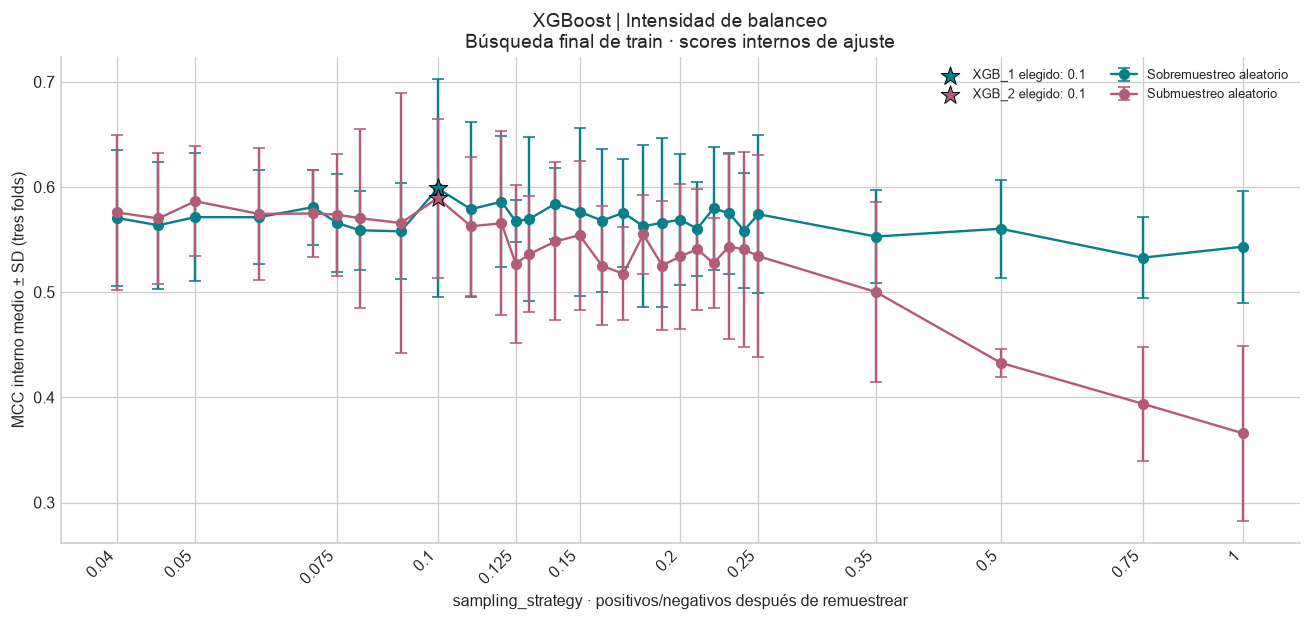

In [9]:
graficar_intensidad('XGB')

Las mejores intensidades internas fueron **0.1 para ROS** y **0.1 para RUS**, con MCC interno medio **0.5987** y **0.5894**. La ampliación explora razones cercanas a la distribución original e intermedias entre las previamente disponibles.

El eje horizontal es logarítmico para distinguir las intensidades pequeñas; las etiquetas conservan su valor exacto. Las barras representan SD entre tres folds, no intervalos de confianza. Los scores ya se usaron para ajustar intensidad y umbral; la gráfica no sustituye la evaluación externa.


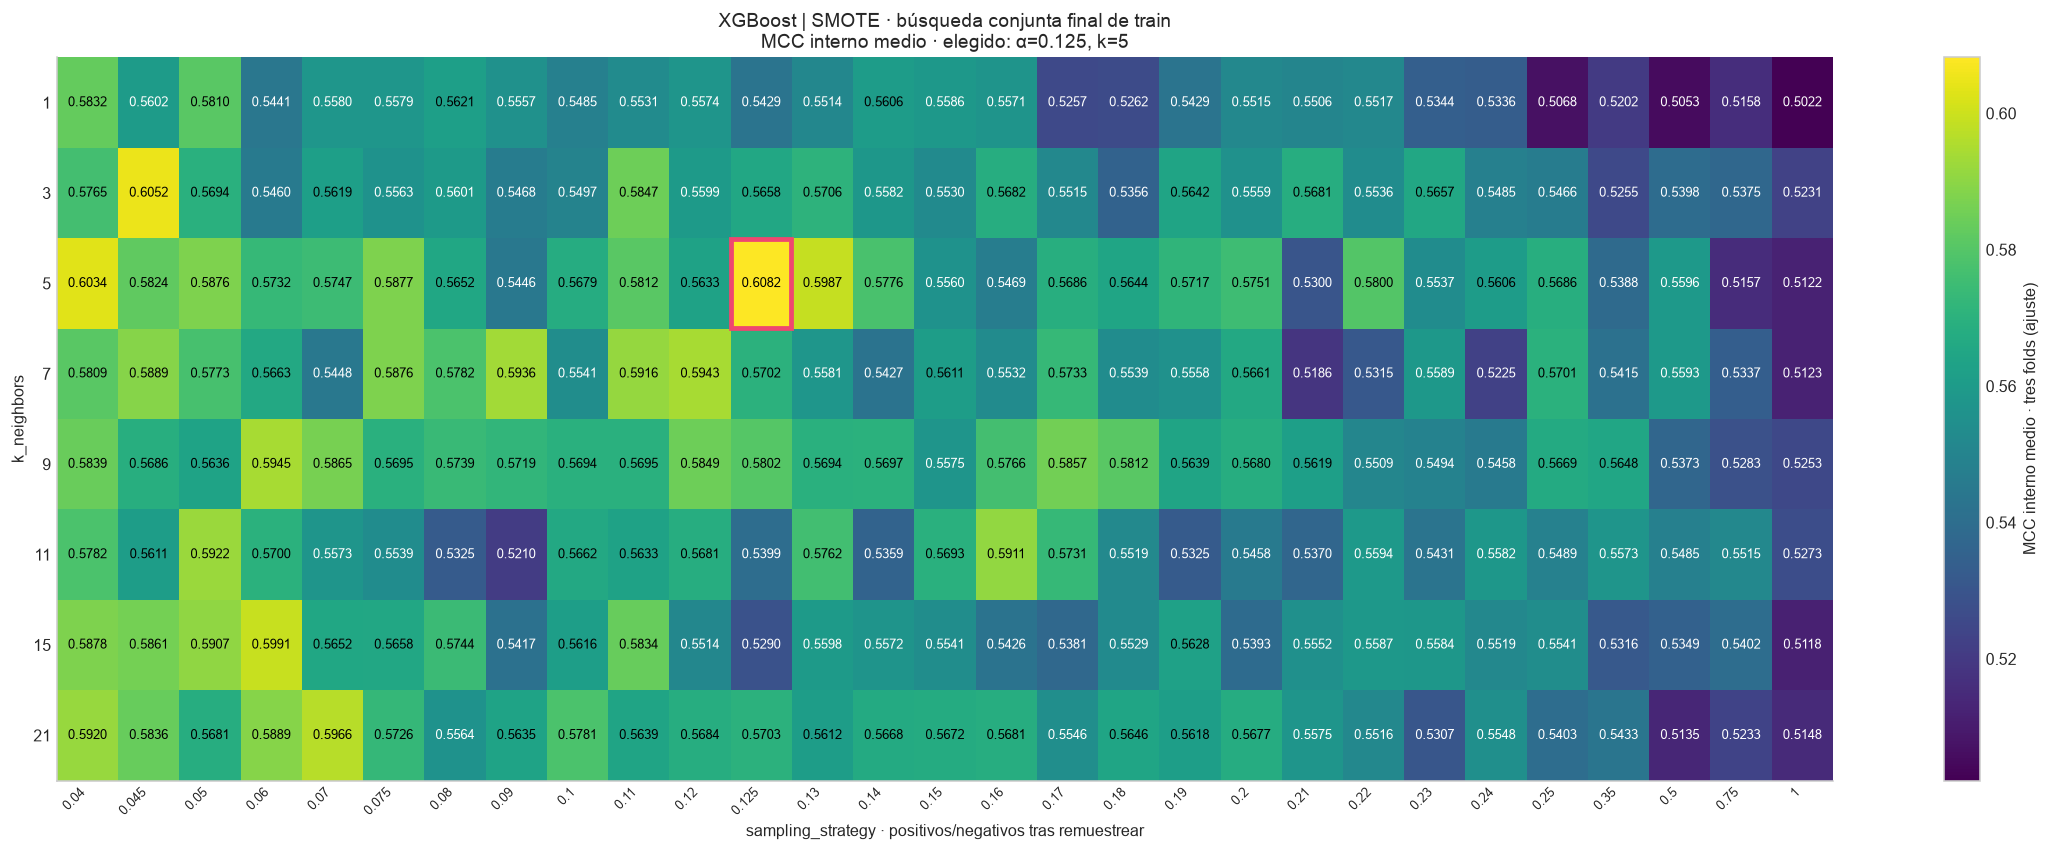

In [10]:
# Scores de ajuste: cada celda usa tres folds internos de train.
mid_smote = f'{FAMILIA}_3'
datos_smote = resumen_busqueda_final.loc[resumen_busqueda_final['ID'] == mid_smote]
matriz = datos_smote.pivot(index='k_neighbors', columns='sampling_strategy',
                           values='MCC_interno_media').reindex(index=K_NEIGHBORS, columns=SAMPLING_STRATEGIES)
factible = datos_smote.pivot(index='k_neighbors', columns='sampling_strategy',
                            values='Factible').reindex(index=K_NEIGHBORS, columns=SAMPLING_STRATEGIES)
valores = matriz.to_numpy(dtype=float)
mascara = (~factible.to_numpy(dtype=bool)) | ~np.isfinite(valores)
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('#d9d9d9')
fig, ax = plt.subplots(figsize=(20, 7.5))
ax.grid(False)
im = ax.imshow(np.ma.array(valores, mask=mascara), cmap=cmap, aspect='auto')
for i, k in enumerate(K_NEIGHBORS):
    for j, a in enumerate(SAMPLING_STRATEGIES):
        if mascara[i, j]:
            ax.text(j, i, 'No factible', ha='center', va='center', fontsize=8, color='#333333')
        else:
            color = 'white' if im.norm(valores[i, j]) < .55 else 'black'
            ax.text(j, i, f'{valores[i,j]:.4f}', ha='center', va='center', color=color, fontsize=8)
mejor = datos_smote.loc[datos_smote['Seleccionado']].iloc[0]
j = SAMPLING_STRATEGIES.index(float(mejor['sampling_strategy']))
i = K_NEIGHBORS.index(int(mejor['k_neighbors']))
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((j-.49, i-.49), .98, .98, fill=False, edgecolor='#ef476f', lw=3))
ax.set_xticks(range(len(SAMPLING_STRATEGIES)), [f'{a:g}' for a in SAMPLING_STRATEGIES],rotation=45,ha='right',fontsize=8)
ax.set_yticks(range(len(K_NEIGHBORS)), K_NEIGHBORS)
ax.set(xlabel='sampling_strategy · positivos/negativos tras remuestrear', ylabel='k_neighbors',
       title=f'{NOMBRE_MODELO} | SMOTE · búsqueda conjunta final de train\n'
             f'MCC interno medio · elegido: α={mejor["sampling_strategy"]:g}, k={int(mejor["k_neighbors"])}')
fig.colorbar(im, ax=ax, label='MCC interno medio · tres folds (ajuste)')
plt.tight_layout()
plt.show()


La mejor pareja interna fue **(sampling_strategy=0.125, k_neighbors=5)**, con MCC medio **0.6082 ± 0.0621**. En la malla anterior se elegía (0.125, 5), con score interno **0.6082**. La diferencia de máximos es de ajuste y no demuestra una mejora de generalización.

El heatmap muestra las **232 parejas** sin separar la búsqueda de intensidad y vecinos. Las diferencias de color corresponden al efecto conjunto de ambos parámetros; el borde identifica la selección. Un máximo en una malla finita no establece un óptimo continuo. La conclusión sobre superar a XGB_0 procede de los cinco folds externos compartidos, no del mayor valor de esta figura.


## 7. Comparación de estrategias mediante CV externa

La clasificación se ordena por MCC promedio de los cinco folds externos, con selección interna del umbral en cada fold. Se desempata por menor SD y luego por ID. Kappa, AP, estabilidad y complejidad complementan la interpretación; una diferencia pequeña de medias no demuestra superioridad estadística.

La columna `Umbral_train` documenta el umbral final obtenido con las OOF de todo train. Las métricas de CV se calcularon con los cinco umbrales internos correspondientes a cada subentrenamiento, que se muestran en la auditoría anterior. No se aplicó retrospectivamente el umbral final a las etiquetas de validación para seleccionar modelos.
En las estrategias con remuestreo, cada MCC externo evalúa la búsqueda interna completa: el sampling_strategy puede variar entre folds. `Sampling_train` es el valor elegido en una nueva búsqueda sobre train completo, y `Sampling_por_fold` permite auditar los valores externos sin usarlos como votación para el modelo final.


In [11]:
metricas_cv = ['Accuracy', 'MCC', 'Kappa', 'Precision', 'Recall', 'F1',
               'ROC_AUC', 'AP', 'Brier', 'LogLoss', 'Prob_media', 'Pred_positivas', 'Umbral']
medias_cv = resultados_cv.groupby('ID')[metricas_cv].mean().add_suffix('_CV')
desv_cv = resultados_cv.groupby('ID')[metricas_cv].std(ddof=1).add_suffix('_SD')
resumen_cv = catalogo.join(medias_cv).join(desv_cv)
resumen_cv['Umbral_train'] = pd.Series(umbrales_fijados)
resumen_cv['Sampling_train'] = pd.Series(sampling_final)
resumen_cv['k_neighbors'] = pd.Series(k_neighbors_final)
resumen_cv['k_por_fold'] = resultados_cv.groupby('ID')['k_neighbors'].agg(list)
resumen_cv['Sampling_por_fold'] = resultados_cv.groupby('ID')['sampling_strategy_seleccionado'].agg(list)
resumen_cv = resumen_cv.sort_values(['MCC_CV', 'MCC_SD'], ascending=[False, True], kind='stable')
# El ID resuelve empates exactos tras MCC y desviación.
resumen_cv = resumen_cv.reset_index().sort_values(
    ['MCC_CV', 'MCC_SD', 'ID'], ascending=[False, True, True]).set_index('ID')
columnas_cv = ['Modelo', 'Estrategia', 'MCC_CV', 'MCC_SD', 'Kappa_CV',
               'AP_CV', 'Recall_CV', 'Precision_CV', 'Accuracy_CV', 'F1_CV', 'ROC_AUC_CV', 'Umbral_train', 'Sampling_train', 'k_neighbors']
for familia in [FAMILIA]:
    print(f'Bloque {familia}: ordenado por MCC de CV')
    tabla(resumen_cv[resumen_cv['Familia'] == familia][columnas_cv])

print('Calidad probabilística de CV: menor Brier/Log Loss es mejor')
tabla(resumen_cv[['Estrategia', 'Brier_CV', 'LogLoss_CV', 'Prob_media_CV']])
ganador_id = resumen_cv.index[0]
mejor_kappa_id = resumen_cv['Kappa_CV'].idxmax()
print(f'Ganador MCC fijado: {ganador_id}; mayor kappa promedio: {mejor_kappa_id}')
# MCC descendente, SD ascendente e ID ascendente, como en el original.
mejor_balanceado_id = resumen_cv.loc[
    resumen_cv.index.isin([f'{FAMILIA}_{j}' for j in range(1, 5)])
].index[0]
comparaciones = {FAMILIA: [f'{FAMILIA}_0', mejor_balanceado_id]}
assert len(set(comparaciones[FAMILIA])) == 2
print(f'Comparación principal: {comparaciones[FAMILIA]}')
print('Configuración final y desempeño externo · N/A identifica ausencia de remuestreo')
resumen_configuraciones = resumen_cv[['Modelo','Estrategia','Sampling_train','k_neighbors','Sampling_por_fold','k_por_fold',
                                     'Umbral_train','MCC_CV','MCC_SD','Kappa_CV','AP_CV','Recall_CV']].copy()
resumen_configuraciones['Sampling_train'] = resumen_configuraciones['Sampling_train'].map(
    lambda valor:'N/A' if pd.isna(valor) else f'{valor:g}')
resumen_configuraciones['Sampling_por_fold'] = resumen_configuraciones['Sampling_por_fold'].map(
    lambda valores:'N/A' if all(pd.isna(v) for v in valores) else ', '.join(f'{v:g}' for v in valores))
resumen_configuraciones['k_por_fold'] = resumen_configuraciones['k_por_fold'].map(
    lambda valores:'N/A' if all(pd.isna(v) for v in valores) else ', '.join(str(int(v)) for v in valores))
tabla(resumen_configuraciones)


Bloque XGB: ordenado por MCC de CV


,Modelo,Estrategia,MCC_CV,MCC_SD,Kappa_CV,AP_CV,Recall_CV,Precision_CV,Accuracy_CV,F1_CV,ROC_AUC_CV,Umbral_train,Sampling_train,k_neighbors
ID,,,,,,,,,,,,,,
XGB_0,XGBoost,Sin balanceo,0.5873,0.1122,0.5827,0.6072,0.5470,0.6618,0.9750,0.5954,0.8989,0.3150,N/A,N/A
XGB_2,XGBoost,Random Undersampling,0.5685,0.1026,0.5587,0.5947,0.5159,0.6660,0.9740,0.5717,0.8935,0.4400,0.1000,N/A
XGB_1,XGBoost,Random Oversampling,0.5679,0.1162,0.5639,0.6090,0.5650,0.6074,0.9715,0.5784,0.8891,0.3500,0.1000,N/A
XGB_3,XGBoost,SMOTE,0.5470,0.1565,0.5384,0.5770,0.5028,0.6351,0.9729,0.5520,0.9031,0.5200,0.1250,5
XGB_4,XGBoost,Ponderación,0.5196,0.1324,0.5082,0.5639,0.4788,0.6131,0.9698,0.5234,0.8922,0.8600,N/A,N/A


Calidad probabilística de CV: menor Brier/Log Loss es mejor


,Estrategia,Brier_CV,LogLoss_CV,Prob_media_CV
ID,,,,
XGB_0,Sin balanceo,0.0200,0.0845,0.0294
XGB_2,Random Undersampling,0.0210,0.0898,0.0442
XGB_1,Random Oversampling,0.0209,0.0931,0.0498
XGB_3,SMOTE,0.0210,0.0893,0.0448
XGB_4,Ponderación,0.0523,0.1969,0.1520


Ganador MCC fijado: XGB_0; mayor kappa promedio: XGB_0
Comparación principal: ['XGB_0', 'XGB_2']
Configuración final y desempeño externo · N/A identifica ausencia de remuestreo


,Modelo,Estrategia,Sampling_train,k_neighbors,Sampling_por_fold,k_por_fold,Umbral_train,MCC_CV,MCC_SD,Kappa_CV,AP_CV,Recall_CV
ID,,,,,,,,,,,,
XGB_0,XGBoost,Sin balanceo,N/A,N/A,N/A,N/A,0.3150,0.5873,0.1122,0.5827,0.6072,0.5470
XGB_2,XGBoost,Random Undersampling,0.1,N/A,"0.045, 0.1, 0.05, 0.07, 0.05",N/A,0.4400,0.5685,0.1026,0.5587,0.5947,0.5159
XGB_1,XGBoost,Random Oversampling,0.1,N/A,"0.21, 0.06, 0.07, 0.21, 0.045",N/A,0.3500,0.5679,0.1162,0.5639,0.6090,0.5650
XGB_3,XGBoost,SMOTE,0.125,5,"0.06, 0.06, 0.07, 0.12, 0.05","11, 5, 7, 21, 11",0.5200,0.5470,0.1565,0.5384,0.5770,0.5028
XGB_4,XGBoost,Ponderación,N/A,N/A,N/A,N/A,0.8600,0.5196,0.1324,0.5082,0.5639,0.4788


**Ninguna estrategia supera la media externa de XGB_0**. El orden por MCC externo medio es: **XGB_0: 0.5873 ± 0.1122**; **XGB_2: 0.5685 ± 0.1026**; **XGB_1: 0.5679 ± 0.1162**; **XGB_3: 0.5470 ± 0.1565**; **XGB_4: 0.5196 ± 0.1324**.

El mejor balanceado es **XGB_2**, con diferencia balanceado menos baseline de **-0.0188**. Se mantiene XGB_0 como configuración recomendada por la regla predefinida. La comparación usa los mismos cinco folds externos y no consulta test. Una diferencia de medias entre cinco folds no demuestra por sí sola superioridad estadística.


In [12]:
# Funciones de presentación: reutilizan las predicciones y métricas originales.
NOMBRES_FAMILIA = {FAMILIA: NOMBRE_MODELO}
COLORES_ROL = ['#32658a', '#c57237']
ESTRATEGIAS_VISUALES = {0: 'Sin balanceo', 1: 'Sobremuestreo aleatorio',
                       2: 'Submuestreo aleatorio', 3: 'SMOTE', 4: 'Ponderación de clases'}
METRICAS_COMPARACION = {
    'MCC': 'MCC', 'Kappa': 'Kappa', 'Precision': 'Precision', 'Recall': 'Recall',
    'F1-score': 'F1', 'Average Precision': 'AP', 'Brier Score': 'Brier', 'Log Loss': 'LogLoss',
}

def etiqueta_config(mid):
    base = f'{mid} · {ESTRATEGIAS_VISUALES[int(mid[-1])]}'
    base += (f' · α={sampling_final[mid]:g}' if pd.notna(sampling_final[mid]) else '')
    return base + (f' · k={int(k_neighbors_final[mid])}' if pd.notna(k_neighbors_final[mid]) else '')

def titulo_bloque(familia):
    return f'{NOMBRES_FAMILIA[familia]} | Baseline vs. mejor estrategia de balanceo'

def graficar_mcc_cv(familia):
    ids = comparaciones[familia]
    datos = resumen_cv.loc[ids]
    fig, ax = plt.subplots(figsize=(9.8, 5.0))
    posiciones = np.arange(2)
    barras = ax.bar(posiciones, datos['MCC_CV'], yerr=datos['MCC_SD'],
                    capsize=6, color=COLORES_ROL, alpha=0.85, width=0.55)
    for j, mid in enumerate(ids):
        valores = resultados_cv.loc[resultados_cv['ID'] == mid, 'MCC'].to_numpy()
        ax.scatter(j+np.linspace(-0.14, 0.14, len(valores)), valores,
                    color='#202b33', edgecolor='white', linewidth=0.5, s=40,
                    zorder=4, label='Cinco folds externos' if j == 0 else None)
        altura = max(float(valores.max()), datos.loc[mid, 'MCC_CV']+datos.loc[mid, 'MCC_SD'])
        ax.text(j, altura+0.025,
                f'{datos.loc[mid, "MCC_CV"]:.4f} ± {datos.loc[mid, "MCC_SD"]:.4f}',
                ha='center', fontsize=10)
    limite = max(0.6, float((datos['MCC_CV']+datos['MCC_SD']).max())+0.14,
                 float(resultados_cv.loc[resultados_cv['ID'].isin(ids), 'MCC'].max())+0.12)
    ax.set_xticks(posiciones, [etiqueta_config(mid).replace(' · ', '\n', 1) for mid in ids])
    ax.set(ylabel='MCC externo · media ± SD y cinco valores individuales',
           title=titulo_bloque(familia)+'\nValidación cruzada de train · umbral ajustado internamente',
           ylim=(0, min(1.05, limite)))
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_umbrales(familia):
    fig, ax = plt.subplots(figsize=(10, 4.9))
    for mid, color in zip(comparaciones[familia], COLORES_ROL):
        sub = curvas_umbral[curvas_umbral['ID'] == mid]
        t = umbrales_fijados[mid]
        valor = resumen_umbrales_train.loc[mid, 'MCC']
        ax.plot(sub['Umbral'], sub['MCC_OOF'], color=color, linewidth=1.9,
                label=f'{etiqueta_config(mid)} · t={t:.3f}, MCC={valor:.3f}')
        ax.scatter(t, valor, s=65, color=color, edgecolor='white', zorder=4)
    ax.set(xlabel='Umbral de clasificación', ylabel='MCC OOF exploratorio · train',
           title=titulo_bloque(familia)+'\nUmbrales seleccionados exclusivamente con OOF de train',
           xlim=(0, 1))
    ax.legend(loc='best', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_metricas_test(familia):
    ids = comparaciones[familia]
    claves = ['MCC', 'Kappa', 'Precision', 'Recall', 'F1', 'AP']
    nombres = ['MCC', 'Kappa', 'Precisión', 'Recall', 'F1-score', 'Precisión media\n(AP)']
    posiciones = np.arange(len(claves))
    fig, ax = plt.subplots(figsize=(10.8, 4.8))
    for j, (mid, color) in enumerate(zip(ids, COLORES_ROL)):
        valores = test_metricas.loc[mid, claves].to_numpy(dtype=float)
        barras = ax.bar(posiciones+(j-0.5)*0.36, valores, width=0.34,
                        color=color, label=etiqueta_config(mid))
        ax.bar_label(barras, labels=[f'{v:.3f}' for v in valores], padding=3, fontsize=8)
    ax.set_xticks(posiciones, nombres)
    ax.set(ylabel='Valor de la métrica · mayor es mejor', ylim=(0, 1.05),
           title=titulo_bloque(familia)+'\nTest · cada modelo con su umbral seleccionado en train')
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_precision_recall(familia):
    fig, ax = plt.subplots(figsize=(9.6, 4.8))
    for mid, color in zip(comparaciones[familia], COLORES_ROL):
        precision, recall, _ = precision_recall_curve(y_test, prob_test[mid])
        ax.step(recall, precision, where='post', color=color, linewidth=1.8,
                label=f'{etiqueta_config(mid)} · AP={test_metricas.loc[mid, "AP"]:.3f}')
    ax.axhline(y_test.mean(), color='#777777', ls='--',
               label=f'Prevalencia real de test: {y_test.mean():.2%}')
    ax.set(xlabel='Recall · clase falla', ylabel='Precisión · clase falla',
           title=titulo_bloque(familia)+'\nPrecision-Recall · probabilidades originales de test',
           xlim=(0, 1), ylim=(0, 1.03))
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_confusiones(familia):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.0), layout='constrained')
    # Misma escala de conteos para ambos modelos para toda la comparación.
    vmax = int((y_test == 0).sum())
    for ax, mid, rol, color in zip(axes, comparaciones[familia],
                                   ['Baseline', 'Mejor balanceado'], COLORES_ROL):
        t = decisiones['umbrales_OOF_train'][mid]
        matriz = confusion_matrix(y_test, prob_test[mid] >= t, labels=[0, 1])
        disp = ConfusionMatrixDisplay(matriz, display_labels=['Sin falla', 'Falla'])
        disp.plot(values_format='d', cmap='Blues', colorbar=False, ax=ax)
        disp.im_.set_clim(0, vmax)
        v = test_metricas.loc[mid]
        ax.set(xlabel='Clase predicha', ylabel='Clase real')
        ax.set_title(f'{rol} · {etiqueta_config(mid)}\n'
                     f'MCC={v["MCC"]:.3f} · precisión={v["Precision"]:.1%} · recall={v["Recall"]:.1%}\n'
                     f'Umbral de train={t:.3f}', fontsize=10, color=color)
    fig.colorbar(disp.im_, ax=axes.tolist(), shrink=0.78, label='Observaciones')
    fig.suptitle(titulo_bloque(familia)+'\nMatrices de confusión · test sin balancear', fontsize=13)
    plt.show()

def graficar_calidad_probabilistica(familia):
    ids = comparaciones[familia]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), layout='constrained')
    for ax, metrica, nombre in zip(axes, ['Brier', 'LogLoss', 'Prob_media'],
                                  ['Brier Score · menor es mejor', 'Log Loss · menor es mejor',
                                   'Probabilidad promedio predicha']):
        valores = test_metricas.loc[ids, metrica].to_numpy(dtype=float)
        barras = ax.bar(range(2), valores, color=COLORES_ROL, width=0.6)
        ax.bar_label(barras, labels=[f'{v:.4f}' for v in valores], padding=4, fontsize=9)
        ax.set_xticks(range(2), [f'Baseline\n{ids[0]}', f'Balanceado\n{ids[1]}'])
        tope = max(float(valores.max()), float(y_test.mean()) if metrica == 'Prob_media' else 0)
        ax.set(ylim=(0, max(0.04, tope*1.35)), title=nombre, ylabel='Valor en test')
        if metrica == 'Prob_media':
            ax.axhline(y_test.mean(), color='#777777', ls='--',
                       label=f'Prevalencia real: {y_test.mean():.2%}')
            ax.legend(fontsize=8, loc='upper left')
    fig.suptitle(titulo_bloque(familia)+'\nTest · '+etiqueta_config(ids[0])+' vs. '+etiqueta_config(ids[1]), fontsize=12)
    plt.show()

def mostrar_bloque_test(familia):
    baseline, balanceado = comparaciones[familia]
    claves = list(METRICAS_COMPARACION.values())
    base = test_metricas.loc[baseline, claves].to_numpy(dtype=float)
    bal = test_metricas.loc[balanceado, claves].to_numpy(dtype=float)
    resumen = pd.DataFrame({'Baseline': base, 'Mejor balanceado': bal, 'Diferencia': bal-base},
                            index=pd.Index(METRICAS_COMPARACION, name='Métrica'))
    tablas_comparacion[familia] = resumen
    print(f'{NOMBRES_FAMILIA[familia]} · resultados finales de test')
    print(f'Baseline: {etiqueta_config(baseline)}; mejor balanceado por CV: {etiqueta_config(balanceado)}')
    tabla(resumen)
    for graficar in [graficar_metricas_test, graficar_precision_recall,
                     graficar_confusiones, graficar_calidad_probabilistica]:
        graficar(familia)


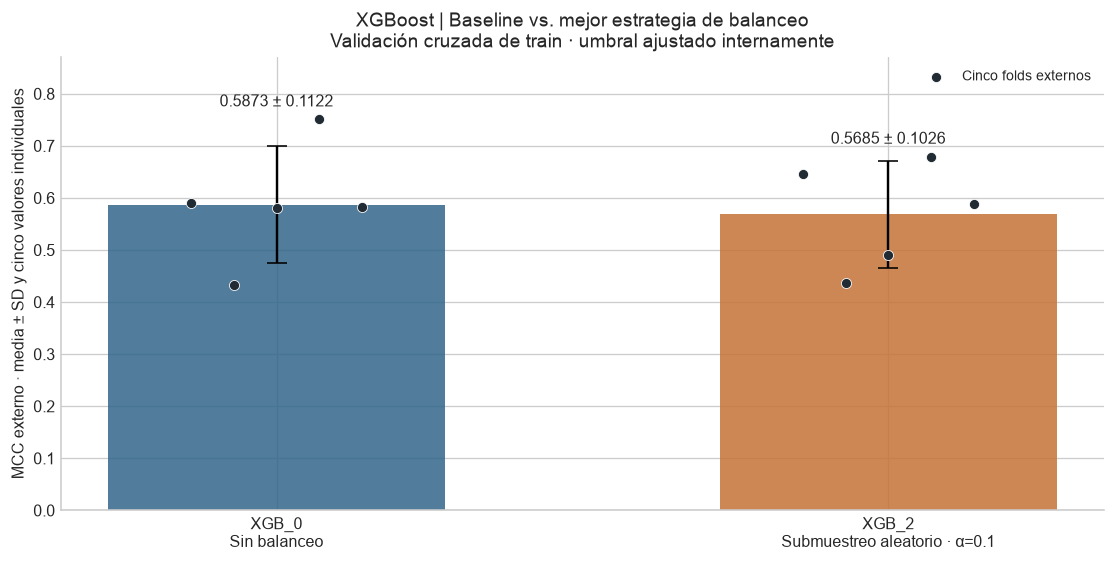

In [13]:
graficar_mcc_cv('XGB')

XGB_0 alcanza MCC externo **0.5873 ± 0.1122**; XGB_2, el mejor balanceado, **0.5685 ± 0.1026**. La diferencia es **-0.0188**. La dispersión y los valores individuales permiten valorar la estabilidad, sin convertir una media mayor en evidencia concluyente de generalización.

En promedio externo, recall cambia **54.7% → 51.6%**, precision **66.2% → 66.6%** y kappa **0.5827 → 0.5587**. La combinación final sobre train es α=0.1; los parámetros internos pueden diferir entre folds.

XGB_2 obtuvo mayor MCC que XGB_0 en **3 de cinco folds**. Este conteo ayuda a contextualizar la diferencia media y no constituye una prueba de significancia.


## 8. Umbrales seleccionados con probabilidades OOF de train

Cada una de las cinco configuraciones recibe su propio umbral final, elegido con sus probabilidades OOF de train para maximizar MCC entre 199 candidatos de 0.005 a 0.995. Ante empate numérico se prefiere el mayor umbral. El término «seleccionado» reconoce que el máximo de esta malla no garantiza el mejor desempeño en datos nuevos.

Se genera una gráfica con dos curvas: XGB_0 frente a la mejor configuración balanceada seleccionada por CV externa. La tabla completa documenta los cinco umbrales. Estos valores se congelan antes de evaluar test; también se usan en las matrices de confusión y las métricas finales.

El MCC OOF de esta tabla es exploratorio porque sus etiquetas se usaron para seleccionar el umbral. La selección de modelos se basa en las cinco evaluaciones externas anteriores, con ajuste del umbral anidado, y no en este máximo exploratorio. El ajuste cambia decisiones, sin cambiar las probabilidades ni su ranking.
Para los modelos con remuestreo, las curvas usan `prob_oof_final`: predicciones de tres folds de la configuración fija elegida en la búsqueda final de train. No se mezclan con las OOF externas, que pueden provenir de distintos sampling_strategy. Las dos configuraciones sin remuestreo conservan sus OOF originales de cinco folds.


In [14]:
ids_umbral = [mid for ids in comparaciones.values() for mid in ids]
curvas_umbral = pd.DataFrame([
    {'ID': mid, 'Umbral': t, 'MCC_OOF': valor}
    for mid in ids_umbral
    for t, valor in zip(MALLA_UMBRALES, curva_mcc(y_train, prob_oof_final[mid]))
])
resumen_umbrales_train = pd.DataFrame([
    {'ID': mid, **evaluar(y_train, prob_oof_final[mid], umbrales_fijados[mid])}
    for mid in modelos
]).set_index('ID')
print('Umbrales finales seleccionados con train · MCC OOF exploratorio')
tabla(catalogo[['Modelo', 'Estrategia']].join(resumen_umbrales_train[
    ['Umbral', 'MCC', 'Kappa', 'Precision', 'Recall', 'F1']]))
umbral_train = resumen_umbrales_train.loc[ids_umbral].reset_index()

Umbrales finales seleccionados con train · MCC OOF exploratorio


,Modelo,Estrategia,Umbral,MCC,Kappa,Precision,Recall,F1
ID,,,,,,,,
XGB_0,XGBoost,Sin balanceo,0.3150,0.5832,0.5706,0.7290,0.4845,0.5821
XGB_1,XGBoost,Random Oversampling,0.3500,0.5935,0.5919,0.6500,0.5652,0.6047
XGB_2,XGBoost,Random Undersampling,0.4400,0.5871,0.5822,0.6800,0.5280,0.5944
XGB_3,XGBoost,SMOTE,0.5200,0.6037,0.5912,0.7500,0.5031,0.6022
XGB_4,XGBoost,Ponderación,0.8600,0.5666,0.5456,0.7553,0.4410,0.5569


Los umbrales finales elegidos con OOF de train son XGB_0: **0.315**; XGB_1: **0.350**; XGB_2: **0.440**; XGB_3: **0.520**; XGB_4: **0.860**. En particular, XGB_3 utiliza α=0.125, k=5 y el corte **0.520**. Un umbral más alto no indica un modelo más confiable: depende de la escala probabilística de cada procedimiento.

Los MCC maximizados de esta tabla son resultados de ajuste del corte. Los modelos se comparan mediante CV externa; test recibe todas estas decisiones ya congeladas.


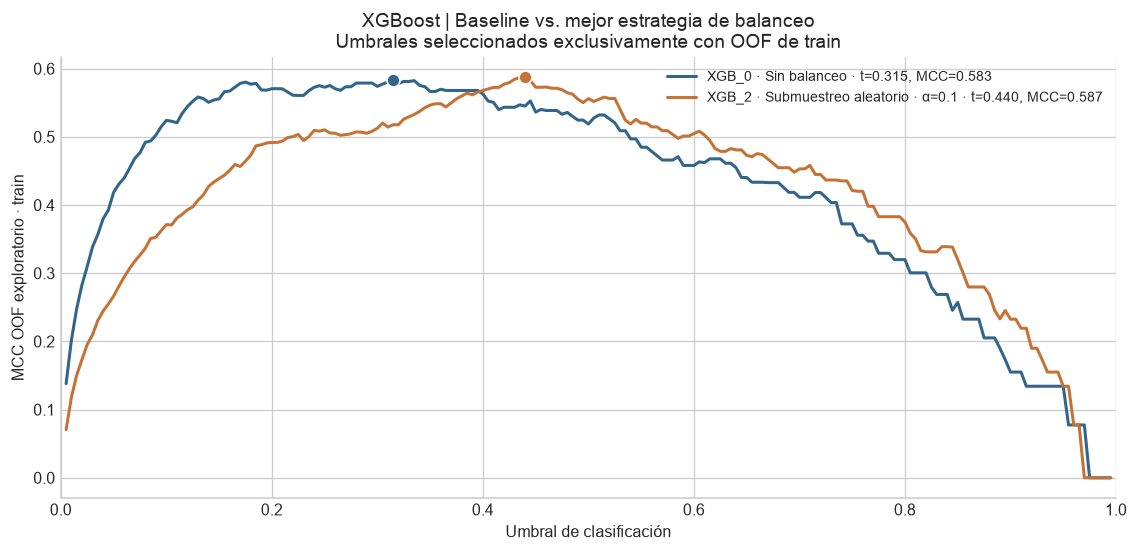

In [15]:
graficar_umbrales('XGB')

La curva de XGB_0 alcanza MCC OOF **0.5832** en **0.315**; la de XGB_2, **0.5871** en **0.440**. En estas curvas, los valores en 0.5 son **0.5188** y **0.5561**; es una referencia descriptiva que no modifica la evaluación principal.

Los máximos se seleccionan con las etiquetas OOF de train. El baseline conserva cinco folds OOF y el procedimiento con remuestreo reutiliza tres de su búsqueda final. Por ello, la comparación principal de generalización se realiza con los cinco folds externos compartidos. Cambiar el corte modifica decisiones, sin cambiar las probabilidades ni su ranking.


## 9. Evaluación y selección de calibradores

Se comparan tres métodos de calibración: NONE (sin calibración), SIGMOID e ISOTONIC, para determinar cuál produce probabilidades de falla más confiables.

La evaluación utiliza validación cruzada de cinco folds. Dentro de cada fold, los calibradores se ajustan mediante otras cinco particiones, evitando utilizar los datos reservados para validación. Si el modelo utiliza remuestreo, este se aplica únicamente durante el entrenamiento.

El mejor método se selecciona por el menor Log Loss promedio, utilizando Brier como segundo criterio. Ambas métricas permiten evaluar la calidad de las probabilidades estimadas. ISOTONIC es más flexible, pero puede sobreajustarse cuando existen pocos casos de falla.

Se eligió Log Loss como métrica principal porque se busca penalizar especialmente las predicciones probabilísticas extremas que resultan incorrectas. Esta métrica asigna una penalización muy elevada cuando el modelo otorga una probabilidad cercana a cero a un evento que finalmente ocurre, o cercana a uno a un evento que no ocurre. Por ello, resulta especialmente útil cuando es importante evitar el exceso de confianza en predicciones equivocadas, por ejemplo, en problemas donde subestimar la probabilidad de una falla puede tener consecuencias importantes.

Por su parte, el Brier Score mide el error cuadrático promedio entre las probabilidades estimadas y los resultados observados. En clasificación binaria, toma valores entre 0 y 1 y ofrece una penalización acotada. Conviene utilizarlo cuando se busca evaluar la calidad global de las probabilidades predichas, sin que los errores extremos dominen tanto la métrica.

Como la calibración modifica las probabilidades, se selecciona un nuevo umbral para cada método. Sin embargo, estos umbrales no se utilizan para elegir el mejor calibrador.

Se conserva ensemble=False: el calibrador se ajusta con predicciones internas OOF y el pipeline se reentrena con todo el subentrenamiento. Los calibradores reciben la prevalencia natural. Esta comparación está condicionada a haber elegido previamente el modelo con los mismos folds externos; no evalúa de forma anidada toda la selección de modelo y calibración.

Si el pipeline recomendado utiliza SMOTE, SeleccionSamplingCV vuelve a seleccionar conjuntamente intensidad y vecinos solo con las filas recibidas por fit. Las etiquetas reservadas para calibración no participan en esa búsqueda. Con ensemble=False, el reajuste sobre train reproduce la pareja de la búsqueda final; NONE reutiliza el modelo original.


In [16]:
METODOS = ['NONE', 'SIGMOID', 'ISOTONIC']

def construir_calibrador(plantilla, metodo, mid=None):
    cv_interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    kwargs = dict(method=metodo.lower(), cv=cv_interna, ensemble=False, n_jobs=1)
    # Compatibilidad explícita con las dos firmas de scikit-learn.
    parametro = ('estimator' if 'estimator' in inspect.signature(CalibratedClassifierCV).parameters
                 else 'base_estimator')
    kwargs[parametro] = (SeleccionSamplingCV(plantilla=clone(plantilla), mid=(ganador_id if mid is None else mid),
                            n_splits=FOLDS_BUSQUEDA)
                         if 'sampler' in plantilla.named_steps else clone(plantilla))
    return CalibratedClassifierCV(**kwargs)

filas_cal_cv = []
prob_cal_oof = {'NONE': prob_oof_final[ganador_id].copy()}
for metodo in METODOS:
    if metodo == 'NONE':
        for fila in filas_cv:
            if fila['ID'] == ganador_id:
                filas_cal_cv.append({'Metodo': metodo, **{k:v for k,v in fila.items() if k != 'ID'}})
        continue
    p_oof = np.full(len(y_train), np.nan)
    for fold, (it, iv) in enumerate(folds, start=1):
        calibrador = construir_calibrador(modelos[ganador_id], metodo)
        calibrador.fit(X_train.iloc[it], y_train.iloc[it])
        p = probabilidad_positiva(calibrador, X_train.iloc[iv])
        p_oof[iv] = p
        filas_cal_cv.append({'Metodo': metodo, 'Fold': fold, **evaluar_probabilidades(y_train.iloc[iv], p)})
    assert np.isfinite(p_oof).all()
    prob_cal_oof[metodo] = p_oof
    print(f'{metodo}: comparación interna terminada (5 externos × 5 internos)')
calibracion_cv_folds = pd.DataFrame(filas_cal_cv)
metricas_prob = ['Brier', 'LogLoss', 'Prob_media', 'Prevalencia', 'AP', 'ROC_AUC']
calibracion_cv = calibracion_cv_folds.groupby('Metodo')[metricas_prob].mean().add_suffix('_CV')
for metrica in ['Brier', 'LogLoss']:
    calibracion_cv[metrica+'_SD'] = calibracion_cv_folds.groupby('Metodo')[metrica].std(ddof=1)
calibracion_cv['Complejidad'] = [METODOS.index(m) for m in calibracion_cv.index]
calibracion_cv = calibracion_cv.sort_values(['LogLoss_CV', 'Brier_CV', 'Complejidad'])
calibrador_elegido = calibracion_cv.index[0]
tabla(calibracion_cv[['Brier_CV', 'Brier_SD', 'LogLoss_CV', 'LogLoss_SD',
                      'Prob_media_CV', 'AP_CV', 'ROC_AUC_CV']])
umbrales_calibracion = {m: seleccionar_umbral(y_train, p) for m, p in prob_cal_oof.items()}
print('Calibrador fijado por train:', calibrador_elegido)
tabla(pd.Series(umbrales_calibracion, name='Umbral_OOF_train').to_frame())
# Se congelan las decisiones antes de entrenar y evaluar sobre test.
decisiones = {
    'ganador_MCC_CV': ganador_id, 'calibrador_train': calibrador_elegido,
    'criterio_calibracion': 'LogLoss promedio CV externa, desempate Brier y complejidad',
    'sampling_strategy_train': {mid:(None if pd.isna(v) else float(v)) for mid,v in sampling_final.items()},
    'k_neighbors_train': {mid:(None if pd.isna(k) else int(k)) for mid,k in k_neighbors_final.items()},
    'umbrales_OOF_train': deepcopy(umbrales_fijados),
    'umbrales_calibracion_OOF_train': deepcopy(umbrales_calibracion),
}
decisiones_congeladas = json.dumps(decisiones, sort_keys=True)
print(json.dumps(decisiones, indent=2, ensure_ascii=False))


SIGMOID: comparación interna terminada (5 externos × 5 internos)
ISOTONIC: comparación interna terminada (5 externos × 5 internos)


,Brier_CV,Brier_SD,LogLoss_CV,LogLoss_SD,Prob_media_CV,AP_CV,ROC_AUC_CV
Metodo,,,,,,,
NONE,0.0200,0.0030,0.0845,0.0095,0.0294,0.6072,0.8989
SIGMOID,0.0204,0.0050,0.0895,0.0167,0.0349,0.6072,0.8989
ISOTONIC,0.0199,0.0048,0.0914,0.0235,0.0350,0.5723,0.8953


Calibrador fijado por train: NONE


,Umbral_OOF_train
NONE,0.3150
SIGMOID,0.3600
ISOTONIC,0.4700


{
  "ganador_MCC_CV": "XGB_0",
  "calibrador_train": "NONE",
  "criterio_calibracion": "LogLoss promedio CV externa, desempate Brier y complejidad",
  "sampling_strategy_train": {
    "XGB_0": null,
    "XGB_1": 0.1,
    "XGB_2": 0.1,
    "XGB_3": 0.125,
    "XGB_4": null
  },
  "k_neighbors_train": {
    "XGB_0": null,
    "XGB_1": null,
    "XGB_2": null,
    "XGB_3": 5,
    "XGB_4": null
  },
  "umbrales_OOF_train": {
    "XGB_0": 0.315,
    "XGB_1": 0.35000000000000003,
    "XGB_2": 0.44,
    "XGB_3": 0.52,
    "XGB_4": 0.86
  },
  "umbrales_calibracion_OOF_train": {
    "NONE": 0.315,
    "SIGMOID": 0.36,
    "ISOTONIC": 0.47000000000000003
  }
}


La calibración se evalúa para **XGB_0**, elegido por MCC externo. La comparación en train es: **NONE: Log Loss 0.08451, Brier 0.02001**; **SIGMOID: Log Loss 0.08948, Brier 0.02040**; **ISOTONIC: Log Loss 0.09145, Brier 0.01989**. Se selecciona **NONE** mediante menor Log Loss externo medio, desempate por Brier y complejidad. La regla probabilística se mantiene idéntica a la versión anterior.

La evaluación está condicionada a haber elegido el modelo con los mismos folds externos. Si utiliza remuestreo, cada ajuste de calibración reoptimiza los parámetros solo con sus filas de entrenamiento. Las etiquetas reservadas para calibrar mantienen su prevalencia natural. Los métodos se muestran aunque no sean los elegidos y los umbrales no intervienen en Log Loss o Brier.


## 10. Reentrenamiento y evaluación final en test


In [17]:
modelos_finales = {mid: clone(plantilla).fit(X_train, y_train)
                   for mid, plantilla in modelos.items()}
calibradores_finales = {'NONE': modelos_finales[ganador_id]}
for metodo in ['SIGMOID', 'ISOTONIC']:
    calibradores_finales[metodo] = construir_calibrador(modelos[ganador_id], metodo).fit(X_train, y_train)

# Primera y única llamada predict_proba sobre test por configuración final.
prob_test = {mid: probabilidad_positiva(estimador, X_test)
             for mid, estimador in modelos_finales.items()}
for estimador in modelos_finales.values():
    verificar_escalado_fit(estimador, X_train, X_test)
prob_cal_test = {'NONE': prob_test[ganador_id]}
for metodo in ['SIGMOID', 'ISOTONIC']:
    prob_cal_test[metodo] = probabilidad_positiva(calibradores_finales[metodo], X_test)

test_metricas = pd.DataFrame({mid: evaluar(y_test, p, decisiones['umbrales_OOF_train'][mid]) for mid, p in prob_test.items()}).T
resumen_test = catalogo.join(test_metricas).reindex(resumen_cv.index)
resumen_test['Sampling_train'] = pd.Series(sampling_final)
resumen_test['k_neighbors'] = pd.Series(k_neighbors_final)
print('Test con umbral propio elegido en train')
tabla(resumen_test[['Modelo', 'Estrategia', 'Sampling_train', 'k_neighbors', 'Umbral', 'Accuracy', 'MCC', 'Kappa', 'Precision',
                    'Recall', 'F1', 'ROC_AUC', 'AP', 'Pred_positivas']])
print('Test: calidad probabilística y desplazamiento de escala por balanceo')
tabla(resumen_test[['Estrategia', 'Brier', 'LogLoss', 'Prob_media', 'Prevalencia']])
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
p_dummy = probabilidad_positiva(dummy, X_test)
metricas_dummy = {**metricas_decision(y_test, dummy.predict(X_test)),
                  **evaluar_probabilidades(y_test, p_dummy)}
tabla(pd.DataFrame([metricas_dummy], index=['Siempre sin falla']))
print('Configuraciones sin predicciones positivas en test:',
      resumen_test.index[resumen_test['Pred_positivas'] == 0].tolist())
assert json.dumps(decisiones, sort_keys=True) == decisiones_congeladas


Test con umbral propio elegido en train


,Modelo,Estrategia,Sampling_train,k_neighbors,Umbral,Accuracy,MCC,Kappa,Precision,Recall,F1,ROC_AUC,AP,Pred_positivas
ID,,,,,,,,,,,,,,
XGB_0,XGBoost,Sin balanceo,N/A,N/A,0.3150,0.9742,0.5158,0.4957,0.6957,0.4000,0.5079,0.9184,0.5900,23.0000
XGB_2,XGBoost,Random Undersampling,0.1000,N/A,0.4400,0.9717,0.5497,0.5495,0.5789,0.5500,0.5641,0.9138,0.5790,38.0000
XGB_1,XGBoost,Random Oversampling,0.1000,N/A,0.3500,0.9692,0.5273,0.5273,0.5366,0.5500,0.5432,0.8977,0.6227,41.0000
XGB_3,XGBoost,SMOTE,0.1250,5,0.5200,0.9758,0.5666,0.5552,0.7037,0.4750,0.5672,0.9114,0.5767,27.0000
XGB_4,XGBoost,Ponderación,N/A,N/A,0.8600,0.9708,0.4227,0.3938,0.6316,0.3000,0.4068,0.9041,0.5160,19.0000


Test: calidad probabilística y desplazamiento de escala por balanceo


,Estrategia,Brier,LogLoss,Prob_media,Prevalencia
ID,,,,,
XGB_0,Sin balanceo,0.0206,0.0823,0.0292,0.0333
XGB_2,Random Undersampling,0.0226,0.0960,0.0618,0.0333
XGB_1,Random Oversampling,0.0199,0.0874,0.0489,0.0333
XGB_3,SMOTE,0.0226,0.0964,0.0628,0.0333
XGB_4,Ponderación,0.0601,0.2233,0.1751,0.0333


,Accuracy,MCC,Kappa,Precision,Recall,F1,Pred_positivas,ROC_AUC,AP,Brier,LogLoss,Prob_media,Prevalencia
Siempre sin falla,0.9667,0.0000,0.0000,0.0000,0.0000,0.0000,0,0.5000,0.0333,0.0333,1.2015,0.0000,0.0333


Configuraciones sin predicciones positivas en test: []


Los resultados finales con umbrales congelados son: **XGB_0: MCC 0.5158, kappa 0.4957, TP=16, FP=7, FN=24**; **XGB_1: MCC 0.5273, kappa 0.5273, TP=22, FP=19, FN=18**; **XGB_2: MCC 0.5497, kappa 0.5495, TP=22, FP=16, FN=18**; **XGB_3: MCC 0.5666, kappa 0.5552, TP=19, FP=8, FN=21**; **XGB_4: MCC 0.4227, kappa 0.3938, TP=12, FP=7, FN=28**.

Las tablas conservan el orden de CV externa; las posiciones observadas en test no cambian el ganador **XGB_0**. Una mejora de decisión puede acompañarse de cambios distintos en AP, Brier o Log Loss. Los vectores de test se calculan una vez por configuración y se reutilizan para métricas y figuras.


## 11. Matrices de confusión y comparación de métricas

Se compara el baseline con el mejor tratamiento balanceado seleccionado por CV externa. Cada uno usa su propio umbral OOF de train, ya congelado.


XGBoost · resultados finales de test
Baseline: XGB_0 · Sin balanceo; mejor balanceado por CV: XGB_2 · Submuestreo aleatorio · α=0.1


,Baseline,Mejor balanceado,Diferencia
Métrica,,,
MCC,0.5158,0.5497,0.0339
Kappa,0.4957,0.5495,0.0538
Precision,0.6957,0.5789,-0.1167
Recall,0.4000,0.5500,0.1500
F1-score,0.5079,0.5641,0.0562
Average Precision,0.5900,0.5790,-0.0110
Brier Score,0.0206,0.0226,0.0020
Log Loss,0.0823,0.0960,0.0138


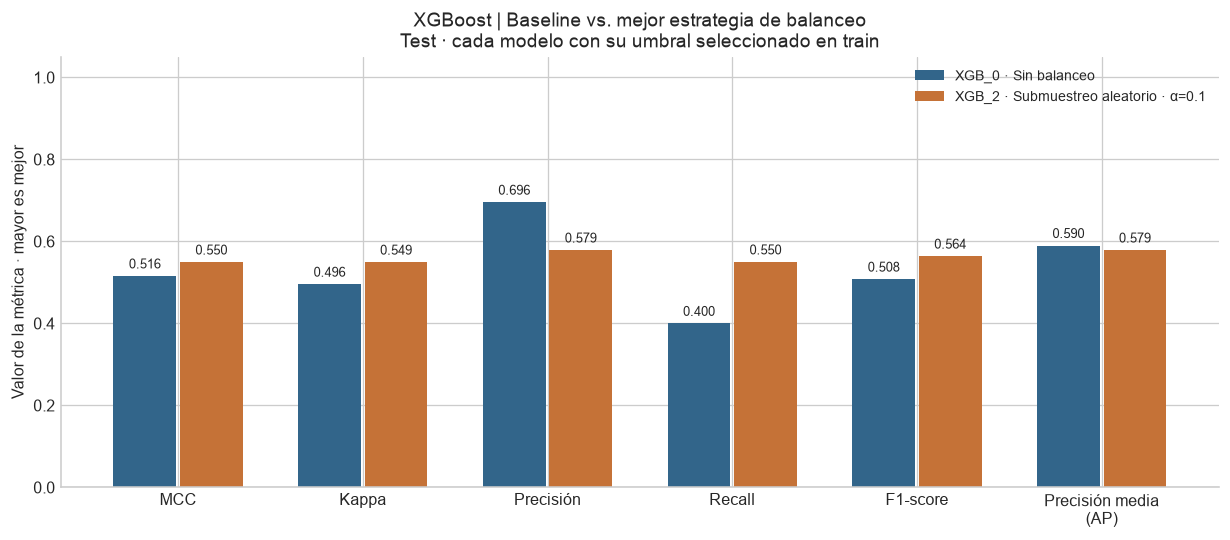

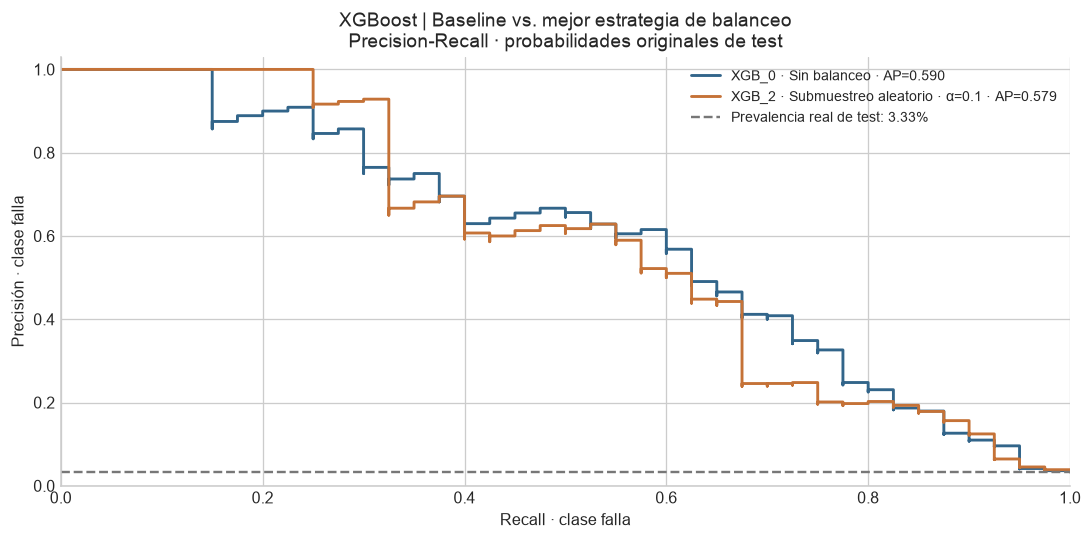

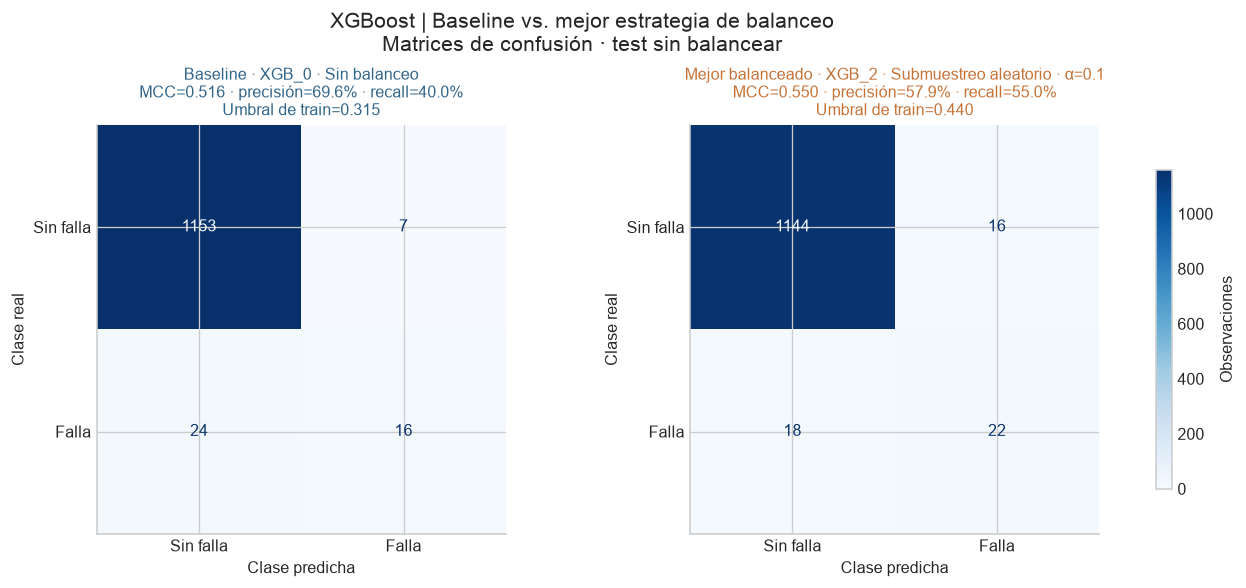

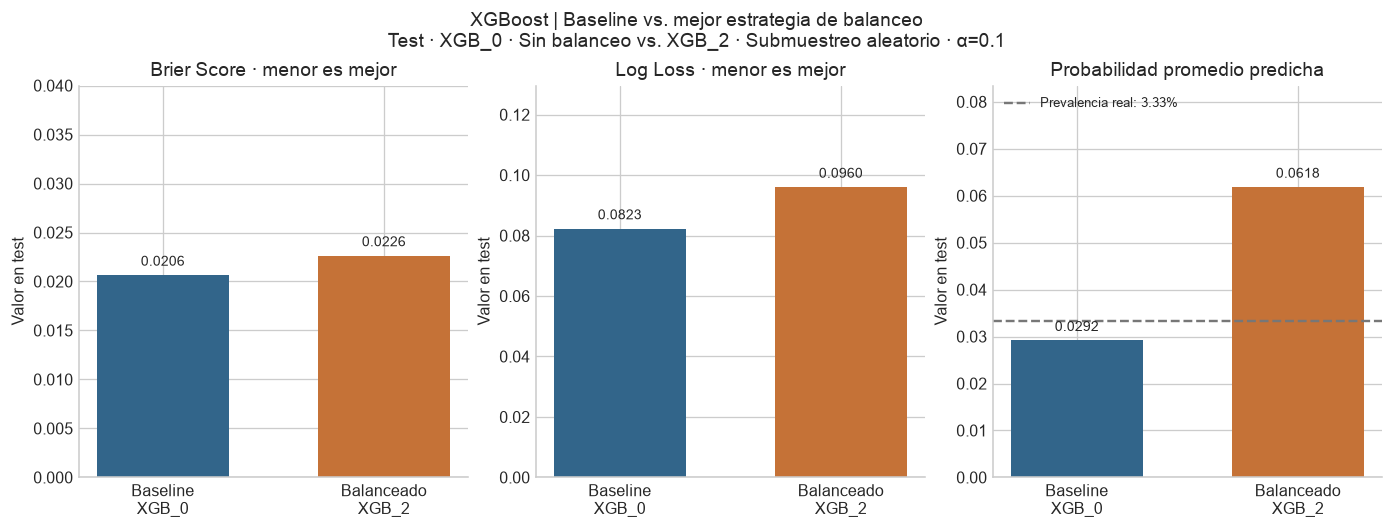

In [18]:
tablas_comparacion = {}
mostrar_bloque_test('XGB')


La comparación principal es **XGB_0 frente a XGB_2 (α=0.1)**, el mejor balanceado por CV. En test, las fallas detectadas cambian **16 → 22**, las omisiones **24 → 18** y las falsas alarmas **7 → 16**. Recall cambia **40.0% → 55.0%** y precision **69.6% → 57.9%**.

MCC cambia **0.5158 → 0.5497**, kappa **0.4957 → 0.5495** y F1 **0.5079 → 0.5641**. AP cambia **0.5900 → 0.5790**. Los resultados corresponden a probabilidades y políticas propias de cada modelo; los compromisos operativos requieren definir costos de omisiones e inspecciones.

Brier cambia **0.02065 → 0.02264** y Log Loss **0.08227 → 0.09602**. Estas pérdidas describen calidad probabilística y no cambian por ajustar el corte. La recomendación sigue siendo la elegida por CV externa, no la que resulte más favorecida por este test.


### Desempeño final de los umbrales seleccionados con train


In [19]:
# Reutilizar métricas finales y mantener separadas las tablas de umbrales por familia.
umbral_test = test_metricas.loc[ids_umbral].rename_axis('ID').reset_index()
for familia, ids in comparaciones.items():
    print(f'{NOMBRES_FAMILIA[familia]} · umbrales de train aplicados a test')
    tabla(umbral_test.loc[umbral_test['ID'].isin(ids),
        ['ID', 'Umbral', 'Accuracy', 'MCC', 'Kappa', 'Precision', 'Recall',
         'F1', 'AP', 'ROC_AUC', 'Brier', 'LogLoss']])
assert set(umbral_test['ID']) == set(ids_umbral)
for mid in modelos:
    assert test_metricas.loc[mid, 'Umbral'] == decisiones['umbrales_OOF_train'][mid]
    referencia_prob = evaluar_probabilidades(y_test, prob_test[mid])
    for metrica in ['AP', 'ROC_AUC', 'Brier', 'LogLoss']:
        assert np.isclose(test_metricas.loc[mid, metrica], referencia_prob[metrica])

XGBoost · umbrales de train aplicados a test


,ID,Umbral,Accuracy,MCC,Kappa,Precision,Recall,F1,AP,ROC_AUC,Brier,LogLoss
0,XGB_0,0.3150,0.9742,0.5158,0.4957,0.6957,0.4000,0.5079,0.5900,0.9184,0.0206,0.0823
1,XGB_2,0.4400,0.9717,0.5497,0.5495,0.5789,0.5500,0.5641,0.5790,0.9138,0.0226,0.0960


Las políticas de XGB_0 y XGB_2 utilizan los umbrales **0.315** y **0.440**, seleccionados con OOF de train. La tabla reproduce las métricas ya calculadas, sin otra búsqueda sobre test.

El ganador por el criterio predefinido es **XGB_0**. Su adopción operativa requiere valorar las fallas omitidas y las falsas alarmas además de MCC. Los resultados actuales describen estas particiones y la malla ampliada; no autorizan ajustar otra vez los parámetros a partir de test.


## 12. Calibración probabilística en test

Un modelo está bien calibrado cuando sus probabilidades se acercan a lo que realmente ocurre. Por ejemplo, si estima un riesgo de falla del 20% para un grupo de componentes, aproximadamente el 20% debería presentar una falla.

Se comparan tres métodos para el modelo seleccionado: NONE (sin calibración), SIGMOID e ISOTONIC, utilizando la opción elegida previamente con train.

Para evaluar la calidad de las probabilidades se utilizan Brier y Log Loss, donde los valores más bajos son mejores. También se consideran AP y ROC-AUC para evaluar qué tan bien el modelo distingue los componentes con mayor riesgo.

Cada método utiliza su propio umbral, seleccionado en train, para evaluar la clasificación en test mediante MCC y kappa.


In [20]:
calibracion_test = pd.DataFrame({m: evaluar(y_test, p, decisiones['umbrales_calibracion_OOF_train'][m]) for m, p in prob_cal_test.items()}).T
calibracion_test = calibracion_test.reindex(METODOS)
calibracion_test['Elegido_en_train'] = calibracion_test.index == calibrador_elegido
columnas_cal = ['Umbral', 'Brier', 'LogLoss', 'Prob_media', 'Prevalencia', 'AP', 'ROC_AUC',
                'MCC', 'Kappa', 'Pred_positivas', 'Elegido_en_train']
tabla(calibracion_test[columnas_cal])
ref_prob = evaluar_probabilidades(y_test, np.full(len(y_test), y_train.mean()))
tabla(pd.DataFrame([ref_prob], index=['Probabilidad constante = prevalencia train'])[
    ['Brier', 'LogLoss', 'Prob_media', 'Prevalencia', 'AP', 'ROC_AUC']])
print('Se mantiene la elección de train:', calibrador_elegido)


,Umbral,Brier,LogLoss,Prob_media,Prevalencia,AP,ROC_AUC,MCC,Kappa,Pred_positivas,Elegido_en_train
NONE,0.3150,0.0206,0.0823,0.0292,0.0333,0.5900,0.9184,0.5158,0.4957,23.0000,True
SIGMOID,0.3600,0.0216,0.0897,0.0317,0.0333,0.5900,0.9184,0.5198,0.4886,20.0000,False
ISOTONIC,0.4700,0.0196,0.0787,0.0326,0.0333,0.5723,0.9188,0.5198,0.4886,20.0000,False


,Brier,LogLoss,Prob_media,Prevalencia,AP,ROC_AUC
Probabilidad constante = prevalencia train,0.0322,0.1461,0.0335,0.0333,0.0333,0.5000


Se mantiene la elección de train: NONE


Para **XGB_0**, las métricas finales son: **NONE: Brier 0.02065, Log Loss 0.08227, MCC 0.5158**; **SIGMOID: Brier 0.02158, Log Loss 0.08967, MCC 0.5198**; **ISOTONIC: Brier 0.01963, Log Loss 0.07871, MCC 0.5198**. Se conserva **NONE**, elegido previamente con train. Las diferencias de Brier y Log Loss se interpretan como calidad probabilística observada; elegir otra transformación por su resultado en test cambiaría el papel del conjunto reservado.

Las métricas de decisión emplean un umbral propio por método, fijado con sus probabilidades OOF. Por eso sus diferencias no se atribuyen únicamente al calibrador. La referencia constante de prevalencia recuerda que una pérdida pequeña en un evento raro no demuestra capacidad para priorizar equipos.


### Curvas de calibración e incertidumbre por grupo

Se utilizan aproximadamente diez grupos por cuantiles para repartir observaciones en una muestra con pocos eventos. `calibration_curve(..., strategy="quantile")` representa la fiabilidad. Los empates, especialmente con Isotonic, pueden reducir el número efectivo de bins.

La tabla complementaria usa `qcut(..., duplicates="drop")` y muestra conteos, fallas, riesgo promedio y frecuencia observada. Los intervalos de Wilson de 95% describen incertidumbre binomial **condicional a los grupos**; no incorporan variación por entrenamiento, selección o dependencia entre sensores. Un grupo con cero fallas no demuestra riesgo cero, y menos de cinco fallas se marca como evidencia escasa.


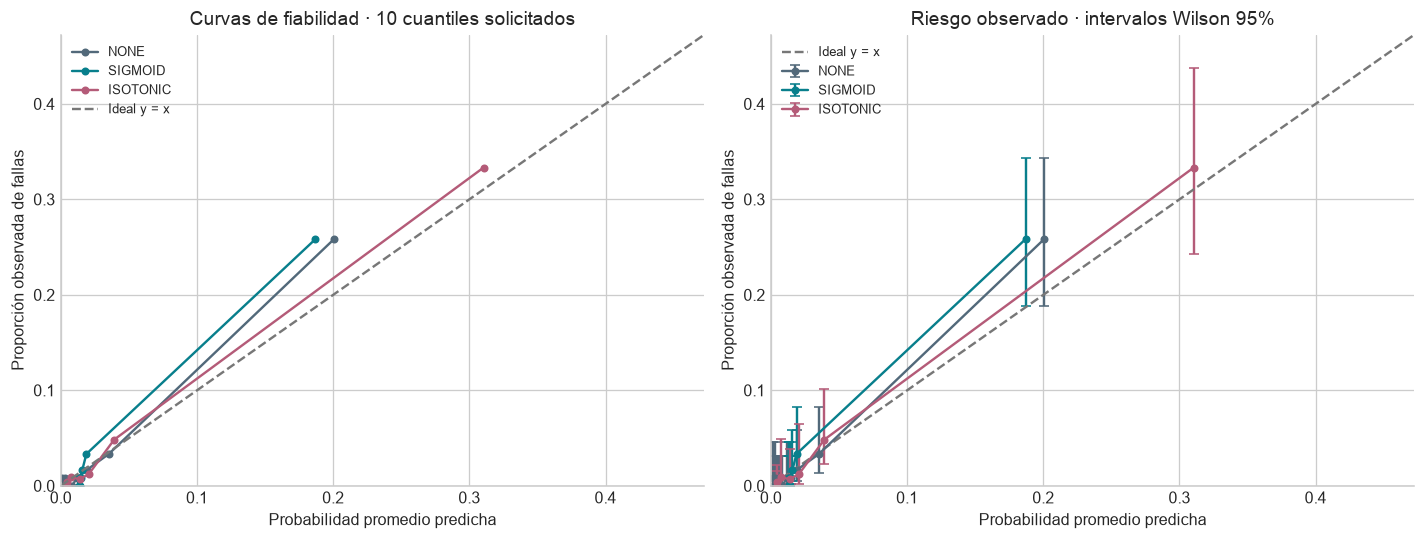

NONE · evidencia por nivel de riesgo


,Metodo,Grupo,N,Fallas,Riesgo_predicho,Riesgo_observado,P_min,P_max,IC95_inf,IC95_sup,Evidencia_escasa
0,NONE,1,120,1,0.0012,0.0083,0.0005,0.0017,0.0015,0.0457,True
1,NONE,2,120,0,0.0022,0.0000,0.0017,0.0026,0.0000,0.0310,True
2,NONE,3,120,1,0.0031,0.0083,0.0026,0.0038,0.0015,0.0457,True
3,NONE,4,120,0,0.0044,0.0000,0.0038,0.0052,0.0000,0.0310,True
4,NONE,5,120,0,0.0060,0.0000,0.0052,0.0069,0.0000,0.0310,True
5,NONE,6,120,0,0.0081,0.0000,0.0069,0.0097,0.0000,0.0310,True
6,NONE,7,120,1,0.0119,0.0083,0.0097,0.0144,0.0015,0.0457,True
7,NONE,8,120,2,0.0191,0.0167,0.0145,0.0250,0.0046,0.0587,True
8,NONE,9,120,4,0.0352,0.0333,0.0251,0.0520,0.0130,0.0826,True
9,NONE,10,120,31,0.2006,0.2583,0.0522,0.9117,0.1884,0.3433,False


SIGMOID · evidencia por nivel de riesgo


,Metodo,Grupo,N,Fallas,Riesgo_predicho,Riesgo_observado,P_min,P_max,IC95_inf,IC95_sup,Evidencia_escasa
10,SIGMOID,1,120,1,0.0130,0.0083,0.0129,0.0131,0.0015,0.0457,True
11,SIGMOID,2,120,0,0.0132,0.0000,0.0131,0.0132,0.0000,0.0310,True
12,SIGMOID,3,120,1,0.0133,0.0083,0.0132,0.0134,0.0015,0.0457,True
13,SIGMOID,4,120,0,0.0135,0.0000,0.0134,0.0136,0.0000,0.0310,True
14,SIGMOID,5,120,0,0.0137,0.0000,0.0136,0.0138,0.0000,0.0310,True
15,SIGMOID,6,120,0,0.0140,0.0000,0.0139,0.0143,0.0000,0.0310,True
16,SIGMOID,7,120,1,0.0146,0.0083,0.0143,0.0150,0.0015,0.0457,True
17,SIGMOID,8,120,2,0.0158,0.0167,0.0150,0.0168,0.0046,0.0587,True
18,SIGMOID,9,120,4,0.0188,0.0333,0.0168,0.0223,0.0130,0.0826,True
19,SIGMOID,10,120,31,0.1870,0.2583,0.0224,0.9959,0.1884,0.3433,False


ISOTONIC · evidencia por nivel de riesgo


,Metodo,Grupo,N,Fallas,Riesgo_predicho,Riesgo_observado,P_min,P_max,IC95_inf,IC95_sup,Evidencia_escasa
20,ISOTONIC,1,480,2,0.0042,0.0042,0.0000,0.0043,0.0011,0.0151,True
21,ISOTONIC,2,171,0,0.0046,0.0000,0.0043,0.0050,0.0000,0.0220,True
22,ISOTONIC,3,112,1,0.0073,0.0089,0.0050,0.0073,0.0016,0.0488,True
23,ISOTONIC,4,143,1,0.0137,0.0070,0.0073,0.0167,0.0012,0.0385,True
24,ISOTONIC,5,83,1,0.0204,0.0120,0.0167,0.0215,0.0021,0.0651,True
25,ISOTONIC,6,124,6,0.0392,0.0484,0.0215,0.0455,0.0224,0.1016,False
26,ISOTONIC,7,87,29,0.3105,0.3333,0.0455,1.0000,0.2432,0.4376,False


In [21]:
def resumen_riesgo(verdad, p, metodo, n_bins=10):
    datos = pd.DataFrame({'y': np.asarray(verdad), 'p': np.asarray(p)})
    grupos = pd.qcut(datos['p'], q=n_bins, duplicates='drop')
    if grupos.cat.categories.size == 0:
        grupos = pd.Series(['Todos'] * len(datos))
    tabla_grupos = datos.groupby(grupos, observed=True).agg(
        N=('y', 'size'), Fallas=('y', 'sum'), Riesgo_predicho=('p', 'mean'),
        Riesgo_observado=('y', 'mean'), P_min=('p', 'min'), P_max=('p', 'max'),
    ).reset_index(drop=True)
    n = tabla_grupos['N'].to_numpy()
    r = tabla_grupos['Riesgo_observado'].to_numpy()
    z = norm.ppf(0.975)
    denominador = 1 + z*z/n
    centro = (r + z*z/(2*n)) / denominador
    semiancho = z*np.sqrt(r*(1-r)/n + z*z/(4*n*n))/denominador
    tabla_grupos['IC95_inf'] = np.maximum(0, centro-semiancho)
    tabla_grupos['IC95_sup'] = np.minimum(1, centro+semiancho)
    tabla_grupos['Evidencia_escasa'] = tabla_grupos['Fallas'] < 5
    tabla_grupos.insert(0, 'Grupo', np.arange(1, len(tabla_grupos)+1))
    tabla_grupos.insert(0, 'Metodo', metodo)
    return tabla_grupos

riesgo_test = pd.concat([resumen_riesgo(y_test, p, m) for m, p in prob_cal_test.items()], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for metodo in METODOS:
    observada, predicha = calibration_curve(y_test, prob_cal_test[metodo], n_bins=10, strategy='quantile')
    axes[0].plot(predicha, observada, marker='o', ms=4, color=COLORES[metodo], label=metodo)
    sub = riesgo_test[riesgo_test['Metodo'] == metodo]
    errores = np.vstack([sub['Riesgo_observado']-sub['IC95_inf'], sub['IC95_sup']-sub['Riesgo_observado']])
    axes[1].errorbar(sub['Riesgo_predicho'], sub['Riesgo_observado'], yerr=errores,
                     marker='o', ms=4, capsize=3, color=COLORES[metodo], label=metodo)
limite = min(1.0, max(0.12, riesgo_test[['Riesgo_predicho', 'IC95_sup']].max().max()*1.08))
for ax, titulo in zip(axes, ['Curvas de fiabilidad · 10 cuantiles solicitados', 'Riesgo observado · intervalos Wilson 95%']):
    ax.plot([0, 1], [0, 1], ls='--', color='#777777', label='Ideal y = x')
    ax.set(xlabel='Probabilidad promedio predicha', ylabel='Proporción observada de fallas',
           title=titulo, xlim=(0, limite), ylim=(0, limite))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for metodo in METODOS:
    print(f'{metodo} · evidencia por nivel de riesgo')
    tabla(riesgo_test[riesgo_test['Metodo'] == metodo])


Los grupos de mayor riesgo muestran: **NONE**: grupo superior con 31 fallas entre 120 casos, riesgo predicho 20.1% y observado 25.8%, IC Wilson [18.8%, 34.3%]; **SIGMOID**: grupo superior con 31 fallas entre 120 casos, riesgo predicho 18.7% y observado 25.8%, IC Wilson [18.8%, 34.3%]; **ISOTONIC**: grupo superior con 29 fallas entre 87 casos, riesgo predicho 31.0% y observado 33.3%, IC Wilson [24.3%, 43.8%].

La proximidad puntual a la diagonal debe leerse junto a los conteos y los intervalos, que no incluyen la incertidumbre por entrenamiento o selección. Los empates de Isotonic pueden cambiar los grupos; sus puntos no necesariamente contienen las mismas observaciones que los de NONE. Con solo 40 eventos en test no se concluye calibración perfecta a partir de una curva.


###  Distribuciones de probabilidades por clase

Cada panel superpone conteos de negativos y positivos en los mismos intervalos. El eje vertical `symlog` conserva los ceros y permite observar la minoría sin normalizar las clases como si fueran igual de frecuentes. Estos histogramas describen separación y desplazamientos de escala; no sustituyen las curvas de fiabilidad.


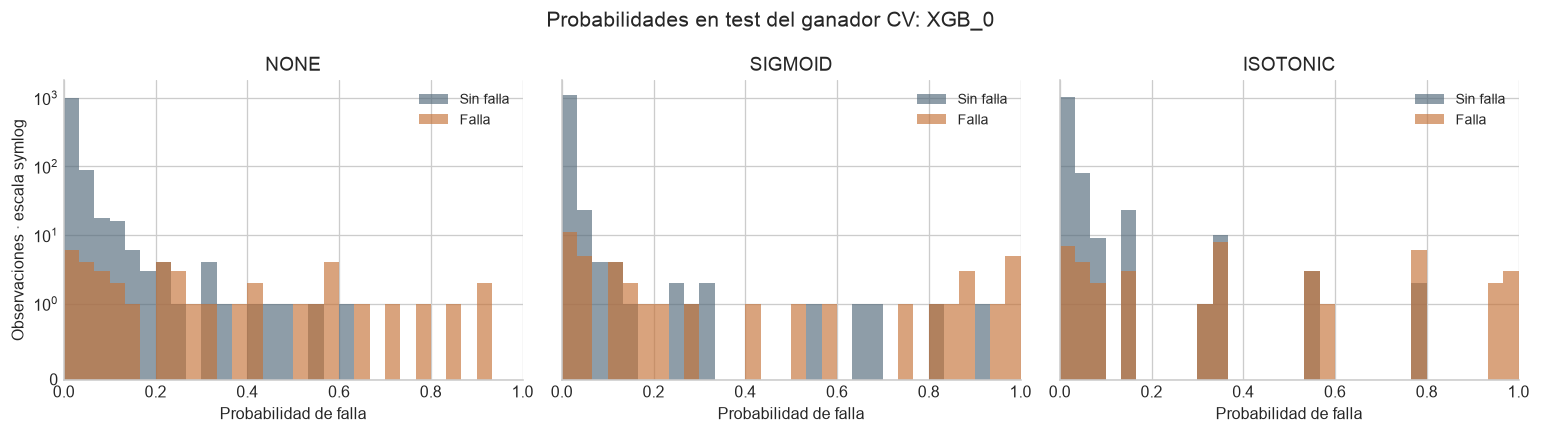

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), sharex=True, sharey=True)
bins = np.linspace(0, 1, 31)
for ax, metodo in zip(axes, METODOS):
    p = prob_cal_test[metodo]
    for clase, color, nombre in [(0, '#52697a', 'Sin falla'), (1, '#c57237', 'Falla')]:
        ax.hist(p[np.asarray(y_test) == clase], bins=bins, color=color,
                 alpha=0.65, histtype='stepfilled', label=nombre)
    ax.set_yscale('symlog', linthresh=1)
    ax.set(title=metodo, xlabel='Probabilidad de falla', xlim=(0, 1))
    ax.legend(fontsize=9)
axes[0].set_ylabel('Observaciones · escala symlog')
fig.suptitle(f'Probabilidades en test del ganador CV: {ganador_id}', fontsize=13)
plt.tight_layout()
plt.show()


Los histogramas muestran cómo cada transformación distribuye los riesgos entre fallas y no fallas. Para NONE, Sigmoid e Isotonic, AP es **0.5900, 0.5900 y 0.5723**, respectivamente. La transformación probabilística puede cambiar la escala y generar empates; el ranking y la fiabilidad se evalúan por separado.

Una probabilidad promedio cercana a prevalencia puede ocultar errores opuestos entre niveles de riesgo. Los histogramas describen separación y concentración; las curvas y conteos describen fiabilidad; MCC y los umbrales describen decisiones. La selección probabilística permanece **NONE**, fijada con train.


## 13. Conclusiones finales

### ¿La malla ampliada supera al modelo sin balanceo?

**Ninguna estrategia supera la media externa de XGB_0**. XGB_0 conserva MCC externo **0.5873 ± 0.1122**; el mejor balanceado es **XGB_2, con 0.5685 ± 0.1026**. La diferencia es **-0.0188**. La regla de selección conserva el modelo sin balanceo. Esto describe la mayor media de estas particiones y no demuestra superioridad estadística ni garantiza mejor generalización.

Los parámetros finales, umbrales y probabilidades de test de las cinco configuraciones se conservaron. Cambiaron las selecciones dentro de los folds externos, por lo que cambia el desempeño estimado del procedimiento de búsqueda. Los cambios de MCC externo frente a la malla anterior de 14 razones fueron **XGB_1: 0.5877 → 0.5679; XGB_2: 0.5738 → 0.5685; XGB_3: 0.5321 → 0.5470**. El baseline conserva los ejemplos originales y utiliza su propio umbral OOF para adaptar la decisión. ROS repite observaciones, RUS elimina negativos y SMOTE interpola casos existentes; estas modificaciones pueden reforzar casos ambiguos o perder información en lugar de mejorar MCC. Son explicaciones plausibles, no causas aisladas por el experimento. Una malla mayor también ofrece más oportunidades de optimizar el score interno sin mejorar necesariamente la evaluación externa.

### Intensidad, vecinos y política de decisión

Las configuraciones finales son **XGB_1: α=0.1; XGB_2: α=0.1; XGB_3: α=0.125, k=5**. Las tres técnicas vuelven a preferir balanceo parcial al completo. La preferencia por una razón dentro de una técnica no implica superar a XGB_0; esa comparación corresponde a la evaluación externa. Los parámetros finales se eligieron con train completo, sin votar entre folds.

SMOTE selecciona conjuntamente intensidad y vecinos. El mejor valor dentro de estas mallas no establece un óptimo continuo ni una regla universal sobre cuántos vecinos utilizar. El umbral también se obtiene con OOF; adaptar el corte modifica decisiones, sin mejorar por sí mismo las probabilidades o su ranking.

### Probabilidades y recomendación

Se recomienda **XGB_0 con NONE y umbral 0.315** según las reglas predefinidas de MCC externo y Log Loss para calibración. Brier y complejidad conservan su función de desempate probabilístico. Las curvas de fiabilidad, el ranking y las matrices de confusión describen dimensiones distintas; los costos de omitir fallas e inspeccionar equipos requieren una política operativa explícita.

En test, el baseline obtiene MCC **0.5158** y el mejor balanceado **0.5497**, con 16 frente a 22 fallas detectadas y 7 frente a 16 falsas alarmas. Esos resultados se reportan con parámetros ya congelados y no modifican la selección.

### Alcance de la evidencia

Los datos son sintéticos y test contiene solo **40 fallas**. Además, esta ampliación se decidió tras observar resultados de CV previos; reutilizar los mismos folds para comparar espacios de búsqueda puede introducir optimismo en la elección del espacio. La CV sigue anidada para ajustar cada candidato, pero la comparación entre versiones debe considerarse exploratoria. Test ya se consultó en versiones anteriores y la calibración está condicionada al modelo elegido.

Confirmar una ventaja requiere datos nuevos, preferentemente separados por tiempo y equipo. El resultado aporta evidencia sobre las mallas y particiones evaluadas, sin justificar que balancear siempre ayude o que mantener el desbalance sea siempre preferible.
